# Lipschitz toy model

Following you will find a simple test of the toy model on a sine function and on a gaussian just to see that it works. For further testing, see the notebook 'Toy_testing.ipynb' which containts a more thorough testing of the limitations of the L-Lipschitz approximations.

In [1]:
import os
import sys
import random
import numpy as np
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import tqdm

import monotonicnetworks as lmn

import matplotlib.pyplot as plt


In [24]:
# "Homemade" modules
%load_ext autoreload
%autoreload 2
from Toy_utils import sine_function_train_data, gaussian_function_data, BasicDataset, calculate_lipschitz_constant, gaussian_lipschitz_constant, FWHM_calculation
from models import LipschitzModel, UnconstrainedModel
from train_eval import train, predict
#from models import UnconstrainedModel, LipschitzModel
#from train_eval import train, evaluate, predict


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Sine function

Testing the Lipschitz performance on a simple sine function. From the Lipschitz condition we should expect a 1-Lipschitz network to be unable to learn a sine function with a frequency higher than 1, while an unconstrained network should not be limited in this way.

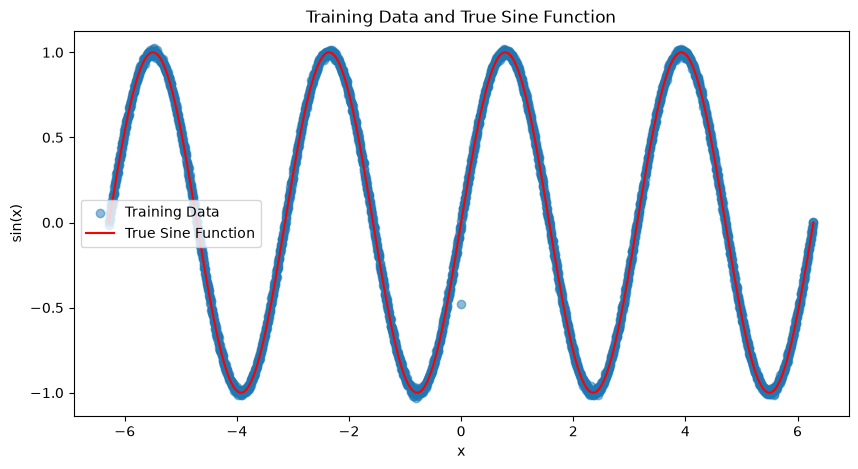

In [ ]:
# Sine function
N = 3000
x_train, y_train, x_linspace, y_linspace = sine_function_train_data(N, frequency=2)

plt.figure(figsize=(10, 5))
plt.scatter(x_train.numpy(), y_train.numpy(), label='Training Data', alpha=0.5)
plt.plot(x_linspace.numpy(), y_linspace.numpy(), color='red', label='True Sine Function')
plt.title('Training Data and True Sine Function')
plt.xlabel('x')
plt.ylabel('sin(x)')
plt.legend()

In [ ]:
# HYPERPARAMETERS
HIDDEN_DIM = 24
N_GROUPS = 8
DEPTH = 5
LEARNING_RATE = 0.0001
NUM_EPOCHS = 5000
MAX_ITER = 1000


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Network
Lipschitz_1_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=1)
Lipschitz_3_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=3)
Unconstrained_model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, depth = DEPTH)

loss_fn = nn.MSELoss()
optimizer_L1 = torch.optim.Adam(Lipschitz_1_model.parameters(), lr=LEARNING_RATE)
optimizer_L3 = torch.optim.Adam(Lipschitz_3_model.parameters(), lr=LEARNING_RATE)
optimizer_unconstrained = torch.optim.Adam(Unconstrained_model.parameters(), lr=LEARNING_RATE)

In [5]:

# Dataset
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42)


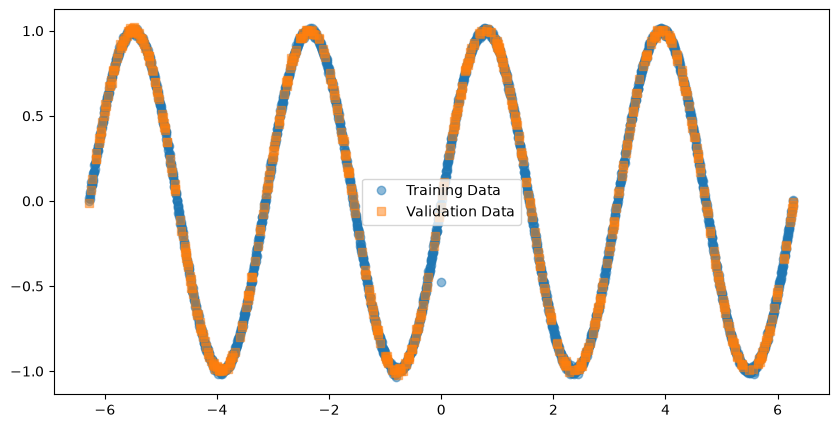

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(x_train.numpy(), y_train.numpy(), 'o', label='Training Data', alpha=0.5)
plt.plot(x_val.numpy(), y_val.numpy(), 's', label='Validation Data', alpha=0.5)
plt.legend()
plt.show()

In [7]:
print(x_train.shape, y_train.shape)
print(x_val.shape, y_val.shape)

torch.Size([2400, 1]) torch.Size([2400, 1])
torch.Size([600, 1]) torch.Size([600, 1])


In [ ]:

train_dataset = BasicDataset(x_train, y_train)
val_dataset = BasicDataset(x_val, y_val)

# Dataloader
trn_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)


In [ ]:
train_losses_L1, val_losses_L1 = train(model =Lipschitz_1_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer_L1,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_L3, val_losses_L3 = train(model =Lipschitz_3_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer_L3,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_unconstrained, val_losses_unconstrained = train(model =Unconstrained_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer_unconstrained,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

Epoch 1
-------------------------------
Epoch 2
-------------------------------
Epoch 3
-------------------------------
Epoch 4
-------------------------------
Epoch 5
-------------------------------
Epoch 6
-------------------------------
Epoch 7
-------------------------------
Epoch 8
-------------------------------
Epoch 9
-------------------------------
Epoch 10
-------------------------------
Epoch 11
-------------------------------
Epoch 12
-------------------------------
Epoch 13
-------------------------------
Epoch 14
-------------------------------
Epoch 15
-------------------------------
Epoch 16
-------------------------------
Epoch 17
-------------------------------
Epoch 18
-------------------------------
Epoch 19
-------------------------------
Epoch 20
-------------------------------
Epoch 21
-------------------------------
Epoch 22
-------------------------------
Epoch 23
-------------------------------
Epoch 24
-------------------------------
Epoch 25
----------------

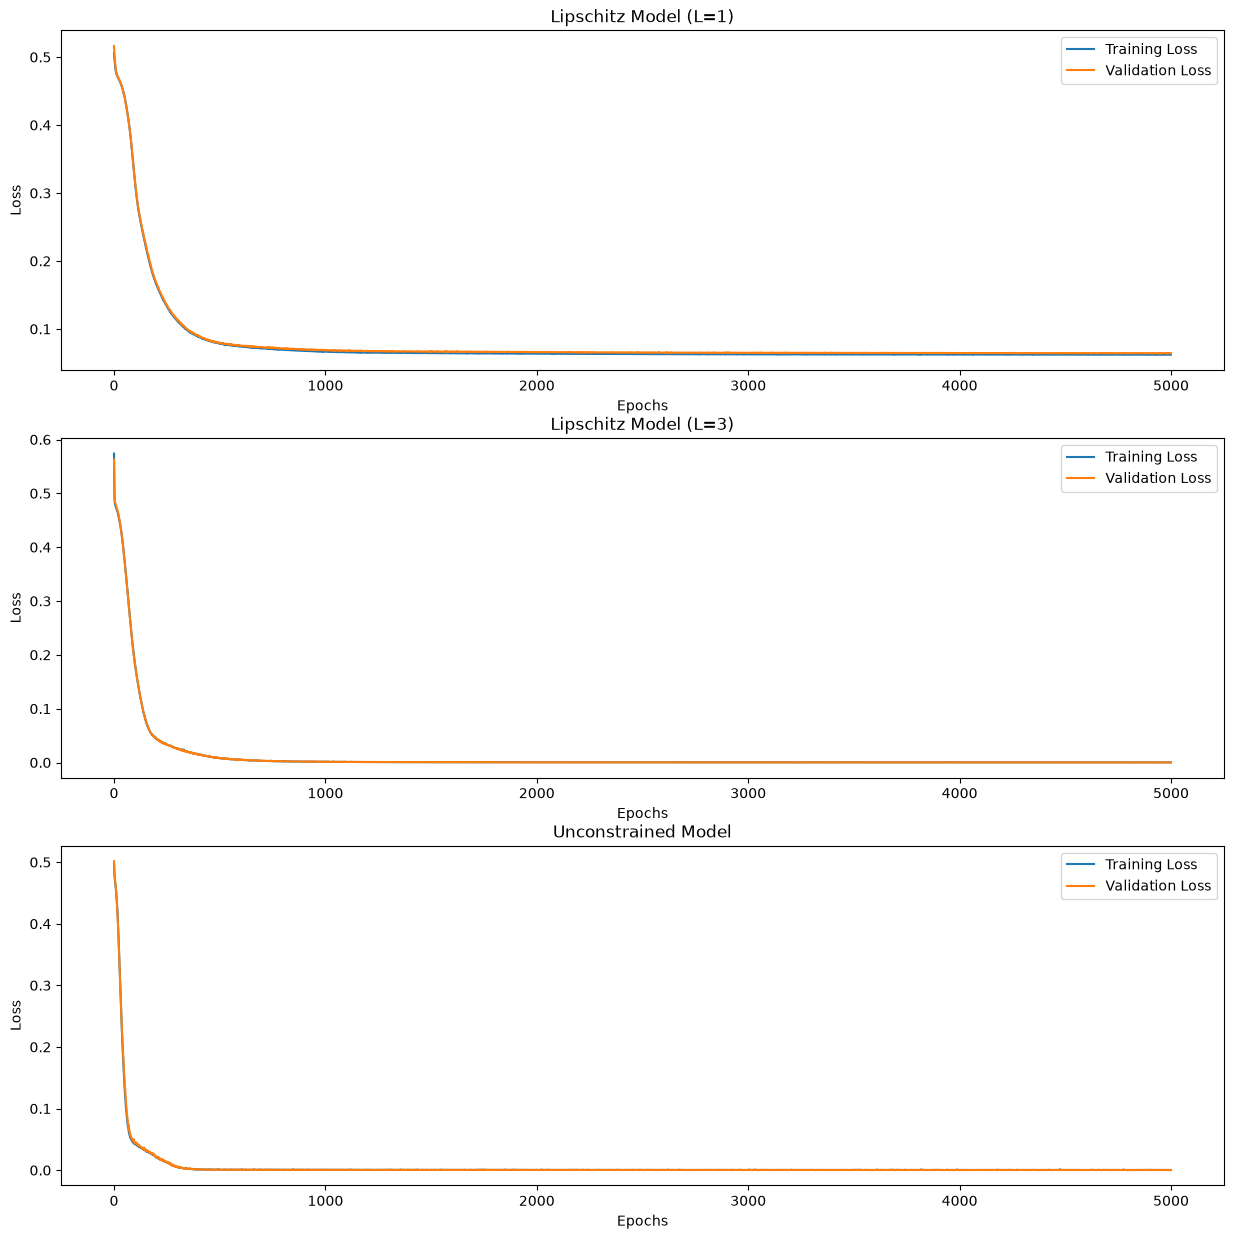

In [11]:
# Plotting training and validation losses
fig, ax = plt.subplots(3, 1, figsize=(15, 15))
ax[0].plot(train_losses_L1, label='Training Loss')
ax[0].plot(val_losses_L1, label='Validation Loss')
ax[0].set_title('Lipschitz Model (L=1)')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss')
ax[1].plot(train_losses_L3, label='Training Loss')
ax[1].plot(val_losses_L3, label='Validation Loss')
ax[1].set_title('Lipschitz Model (L=3)')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Loss')
ax[2].plot(train_losses_unconstrained, label='Training Loss')
ax[2].plot(val_losses_unconstrained, label='Validation Loss')
ax[2].set_title('Unconstrained Model')
ax[2].set_xlabel('Epochs')
ax[2].set_ylabel('Loss')
for a in ax:
    a.legend()

plt.savefig('Plots/sine_losses_plot.pdf')
plt.show()


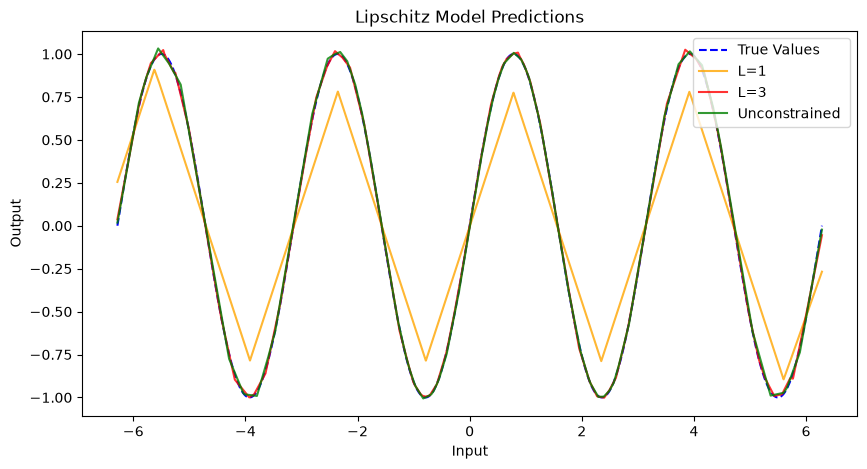

In [ ]:
# Plotting predictions
predictions_1_lipschitz = Lipschitz_1_model(torch.Tensor(x_linspace).view(-1, 1)).detach().numpy()
predictions_3_lipschitz = Lipschitz_3_model(x_linspace).detach().numpy()
predictions_unconstrained = Unconstrained_model(x_linspace).detach().numpy()

plt.figure(figsize=(10, 5))
plt.plot(x_linspace, y_linspace, '--', label='True Values', color='blue')
plt.plot(x_linspace, predictions_1_lipschitz,'-', label='L=1',  color='orange', alpha=0.8)
plt.plot(x_linspace, predictions_3_lipschitz, '-', label='L=3', color='red', alpha=0.8)
plt.plot(x_linspace, predictions_unconstrained,'-', label='Unconstrained ', color='green', alpha=0.8)
plt.xlabel('Input')
plt.ylabel('Output')
plt.legend()
plt.savefig("Plots/sine_fits.pdf")

plt.title('Lipschitz Model Predictions')
plt.show()



In [23]:

# Calculation of predicted Lipschitz constants
lipschitz_constant_L1 = Toy_utils.calculate_lipschitz_constant(Lipschitz_1_model, x_linspace)
lipschitz_constant_L3 = Toy_utils.calculate_lipschitz_constant(Lipschitz_3_model, x_linspace)
lipschitz_constant_unconstrained = Toy_utils.calculate_lipschitz_constant(Unconstrained_model, x_linspace)

print(f"Lipschitz constant of the trained model with L=1: {lipschitz_constant_L1:.4f}")
print(f"Lipschitz constant of the trained model with L=3: {lipschitz_constant_L3:.4f}")
print(f"Lipschitz constant of the trained unconstrained model: {lipschitz_constant_unconstrained:.4f}")

Lipschitz constant of the trained model with L=1: 0.9996
Lipschitz constant of the trained model with L=3: 1.9977
Lipschitz constant of the trained unconstrained model: 2.5397


In [30]:
x_linspace = x_linspace.detach().numpy()

<>:3: SyntaxWarning: invalid escape sequence '\h'
<>:3: SyntaxWarning: invalid escape sequence '\h'
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/3550661950.py:3: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(x_linspace, predictions_1_lipschitz,'-', label=f'L=1, $\hat{{L}}=${lipschitz_constant_L1:.2f} ',  color='orange', alpha=0.8)


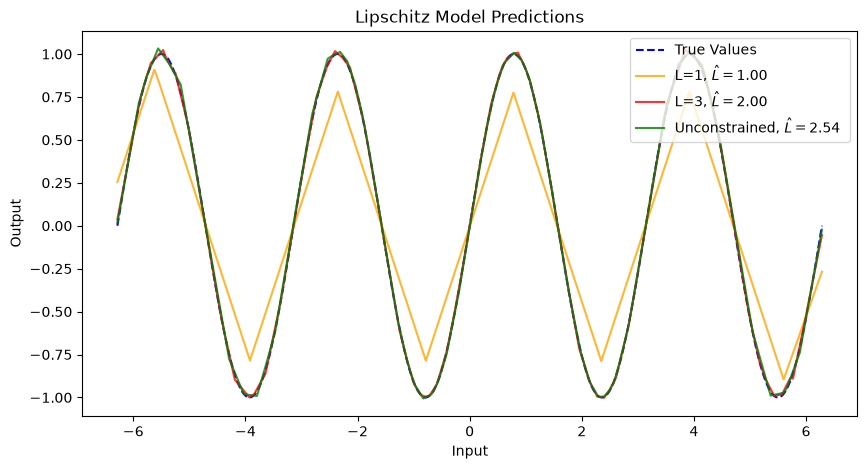

In [43]:
plt.figure(figsize=(10, 5))
plt.plot(x_linspace, y_linspace, '--', label='True Values', color='blue')
plt.plot(x_linspace, predictions_1_lipschitz,'-', label=f'L=1, $\hat{{L}}=${lipschitz_constant_L1:.2f} ',  color='orange', alpha=0.8)
plt.plot(x_linspace, predictions_3_lipschitz, '-', label=rf'L=3, $\hat{{L}}=${lipschitz_constant_L3:.2f} ', color='red', alpha=0.8)
plt.plot(x_linspace, predictions_unconstrained,'-', label=rf'Unconstrained, $\hat{{L}}=${lipschitz_constant_unconstrained:.2f} ', color='green', alpha=0.8)
plt.xlabel('Input')
plt.ylabel('Output')
plt.legend(loc = 'upper right')
plt.savefig("Plots/sine_fits.pdf")
plt.title('Lipschitz Model Predictions')
plt.show()

<>:16: SyntaxWarning: invalid escape sequence '\h'
<>:17: SyntaxWarning: invalid escape sequence '\h'
<>:18: SyntaxWarning: invalid escape sequence '\h'
<>:16: SyntaxWarning: invalid escape sequence '\h'
<>:17: SyntaxWarning: invalid escape sequence '\h'
<>:18: SyntaxWarning: invalid escape sequence '\h'
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/1851831182.py:16: SyntaxWarning: invalid escape sequence '\h'
  plt.hist(abs_errors_L1, bins=30, alpha=0.5, label=f'L=1, $\hat{{L}}=${mean_abs_error_L1:.3f} ', color='orange', density=True)
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/1851831182.py:17: SyntaxWarning: invalid escape sequence '\h'
  plt.hist(abs_errors_L3, bins=30, alpha=0.5, label=f'L=3, $\hat{{L}}=${mean_abs_error_L3:.3f} ', color='red', density=True)
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/1851831182.py:18: SyntaxWarning: invalid escape sequence '\h'
  plt.hist(abs_errors_unconstrained, bins=30, alpha=0.5, lab

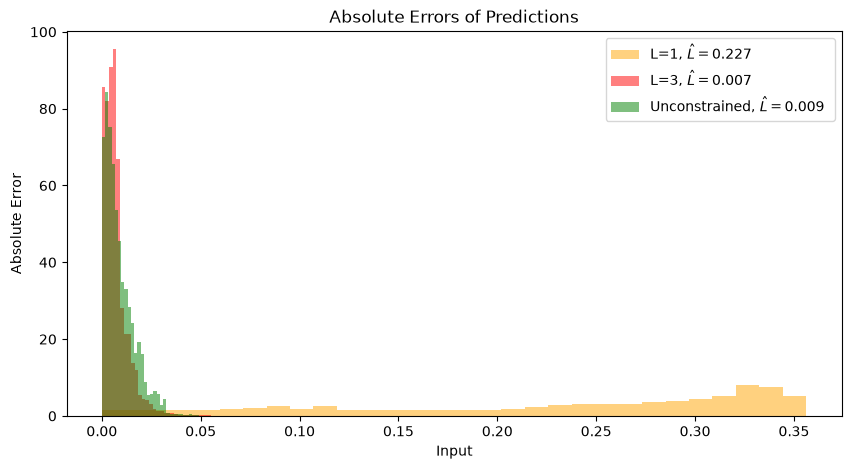

Mean Absolute Error (L1 model): tensor(0.2265)
Mean Absolute Error (L3 model): tensor(0.0070)
Mean Absolute Error (Unconstrained Model): tensor(0.0089)


In [45]:
# Errors
errors_L1 = y_linspace - predictions_1_lipschitz
errors_L3 = y_linspace - predictions_3_lipschitz
errors_unconstrained = y_linspace - predictions_unconstrained

abs_errors_L1 = np.abs(errors_L1)
abs_errors_L3 = np.abs(errors_L3)
abs_errors_unconstrained = np.abs(errors_unconstrained)

mean_abs_error_L1 = torch.mean(abs_errors_L1)
mean_abs_error_L3 = torch.mean(abs_errors_L3)
mean_abs_error_unconstrained = torch.mean(abs_errors_unconstrained)

# Plotting absolute errors
plt.figure(figsize=(10, 5))
plt.hist(abs_errors_L1, bins=30, alpha=0.5, label=f'L=1, $\hat{{L}}=${mean_abs_error_L1:.3f} ', color='orange', density=True)
plt.hist(abs_errors_L3, bins=30, alpha=0.5, label=f'L=3, $\hat{{L}}=${mean_abs_error_L3:.3f} ', color='red', density=True)
plt.hist(abs_errors_unconstrained, bins=30, alpha=0.5, label=f'Unconstrained, $\hat{{L}}=${mean_abs_error_unconstrained:.3f} ', color='green', density=True)
plt.xlabel('Input')
plt.ylabel('Absolute Error')
plt.legend()
plt.savefig("Plots/sine_abs_errors.pdf")
plt.title('Absolute Errors of Predictions')
plt.show()

print("Mean Absolute Error (L1 model):", mean_abs_error_L1)
print("Mean Absolute Error (L3 model):", mean_abs_error_L3)
print("Mean Absolute Error (Unconstrained Model):", mean_abs_error_unconstrained)

## Gaussian function

Using a sharp gaussian function in order to test the performance and limits of the Lipschitz constrained model.

Lipschitz constant of the Gaussian function with sigma=0.1: 24.1971


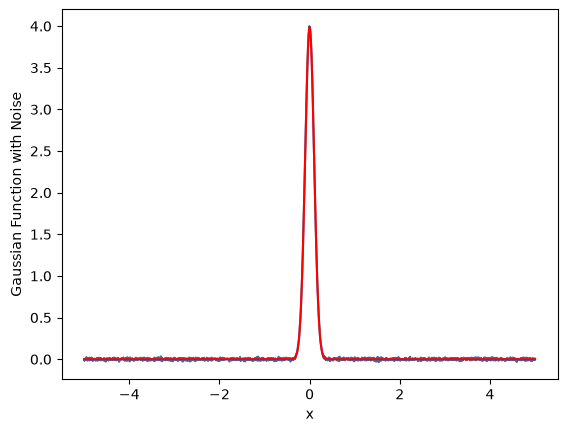

In [30]:
N = 2000
MU = 0
SIGMA = 0.1
NOISE_MAGNITUDE = 0.01

x_gaussian_train, y_gaussian_train, x_gaussian_linspace, y_gaussian_linspace = gaussian_function_data(N=N, mu=MU, sigma=SIGMA, noise_magnitude=NOISE_MAGNITUDE)
plt.plot(x_gaussian_train.numpy(), y_gaussian_train.numpy())
plt.xlabel('x')
plt.ylabel('Gaussian Function with Noise')
plt.plot(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), color='red', label='True Gaussian Function')
print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {gaussian_lipschitz_constant(SIGMA):.4f}")

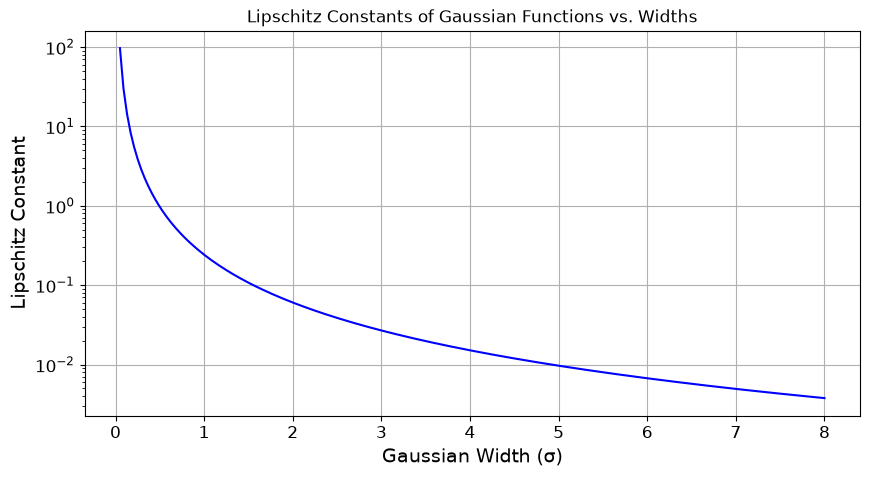

In [31]:

sigma_arrays = np.linspace(0.05, 8.0, 200)  # Gaussian widths
lipschitz_arrays = gaussian_lipschitz_constant(sigma_arrays)  # Lipschitz constants

plt.figure(figsize=(10, 5))
plt.plot(sigma_arrays, lipschitz_arrays, '-', color='blue')

plt.xlabel('Gaussian Width (σ)', fontsize=14)
plt.ylabel('Lipschitz Constant', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.yscale('log')
plt.grid()
plt.savefig('Plots/gaussian_lipschitz_constants.pdf')
plt.title('Lipschitz Constants of Gaussian Functions vs. Widths')
plt.show()

The Lipschitz constant of the gaussian is inversely proportional to the standard deviation $\sigma$ of the gaussian. The sharper the gaussian, the higher the Lipschitz constant. 

In [32]:
# Splitting data into training and validation sets
x_gaussian_train, x_gaussian_val, y_gaussian_train, y_gaussian_val = train_test_split(x_gaussian_train, y_gaussian_train, test_size=0.2, random_state=42)

# Dataloaders for Gaussian data
train_gaussian_dataset = BasicDataset(x_gaussian_train, y_gaussian_train)
val_gaussian_dataset = BasicDataset(x_gaussian_val, y_gaussian_val)

train_gaussian_loader = DataLoader(train_gaussian_dataset, batch_size=32, shuffle=True)
val_gaussian_loader = DataLoader(val_gaussian_dataset, batch_size=32, shuffle=False)

In [33]:
# Setting up contrasting models
HIDDEN_DIM = 24
N_GROUPS = 8
DEPTH = 5
LEARNING_RATE = 0.0001

Lipschitz_1_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=1)
Lipschitz_3_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=3)
Lipschitz_10_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=10)
Lipschitz_20_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=20)
Unconstrained_model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, depth = DEPTH)

loss_fn = nn.MSELoss()
optimizer_L1 = torch.optim.Adam(Lipschitz_1_model.parameters(), lr=LEARNING_RATE)
optimizer_L3 = torch.optim.Adam(Lipschitz_3_model.parameters(), lr=LEARNING_RATE)
optimizer_L10 = torch.optim.Adam(Lipschitz_10_model.parameters(), lr=LEARNING_RATE)
optimizer_L20 = torch.optim.Adam(Lipschitz_20_model.parameters(), lr=LEARNING_RATE)
optimizer_unconstrained = torch.optim.Adam(Unconstrained_model.parameters(), lr=LEARNING_RATE)

In [35]:
# Training and evaluating the models on the Gaussian data
NUM_EPOCHS = 1000
MAX_ITER = 100
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_losses_L1, val_losses_L1 = train(model =Lipschitz_1_model,
    train_loader = train_gaussian_loader,
    val_loader = val_gaussian_loader,
    optimizer = optimizer_L1,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_L3, val_losses_L3 = train(model =Lipschitz_3_model,
    train_loader = train_gaussian_loader,
    val_loader = val_gaussian_loader,
    optimizer = optimizer_L3,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_L10, val_losses_L10 = train(model =Lipschitz_10_model,
    train_loader = train_gaussian_loader,
    val_loader = val_gaussian_loader,
    optimizer = optimizer_L10,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_L20, val_losses_L20 = train(model =Lipschitz_20_model,
    train_loader = train_gaussian_loader,
    val_loader = val_gaussian_loader,
    optimizer = optimizer_L20,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_unconstrained, val_losses_unconstrained = train(model =Unconstrained_model,
    train_loader = train_gaussian_loader,
    val_loader = val_gaussian_loader,
    optimizer = optimizer_unconstrained,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

Epoch 1: Train Loss: 0.1799, Val Loss: 0.1082
Epoch 51: Train Loss: 0.1795, Val Loss: 0.1080
Epoch 101: Train Loss: 0.1795, Val Loss: 0.1077
Epoch 151: Train Loss: 0.1794, Val Loss: 0.1079
Epoch 201: Train Loss: 0.1794, Val Loss: 0.1079
Epoch 251: Train Loss: 0.1794, Val Loss: 0.1080
Epoch 301: Train Loss: 0.1794, Val Loss: 0.1080
Epoch 351: Train Loss: 0.1793, Val Loss: 0.1080
Epoch 401: Train Loss: 0.1794, Val Loss: 0.1081
Early stopping triggered.
Epoch 1: Train Loss: 0.4380, Val Loss: 0.2786
Epoch 51: Train Loss: 0.1895, Val Loss: 0.1126
Epoch 101: Train Loss: 0.1359, Val Loss: 0.0826
Epoch 151: Train Loss: 0.1180, Val Loss: 0.0711
Epoch 201: Train Loss: 0.1114, Val Loss: 0.0673
Epoch 251: Train Loss: 0.1094, Val Loss: 0.0664
Epoch 301: Train Loss: 0.1086, Val Loss: 0.0658
Epoch 351: Train Loss: 0.1084, Val Loss: 0.0658
Epoch 401: Train Loss: 0.1082, Val Loss: 0.0654
Epoch 451: Train Loss: 0.1081, Val Loss: 0.0653
Epoch 501: Train Loss: 0.1081, Val Loss: 0.0655
Early stopping trigg

<function matplotlib.pyplot.show(close=None, block=None)>

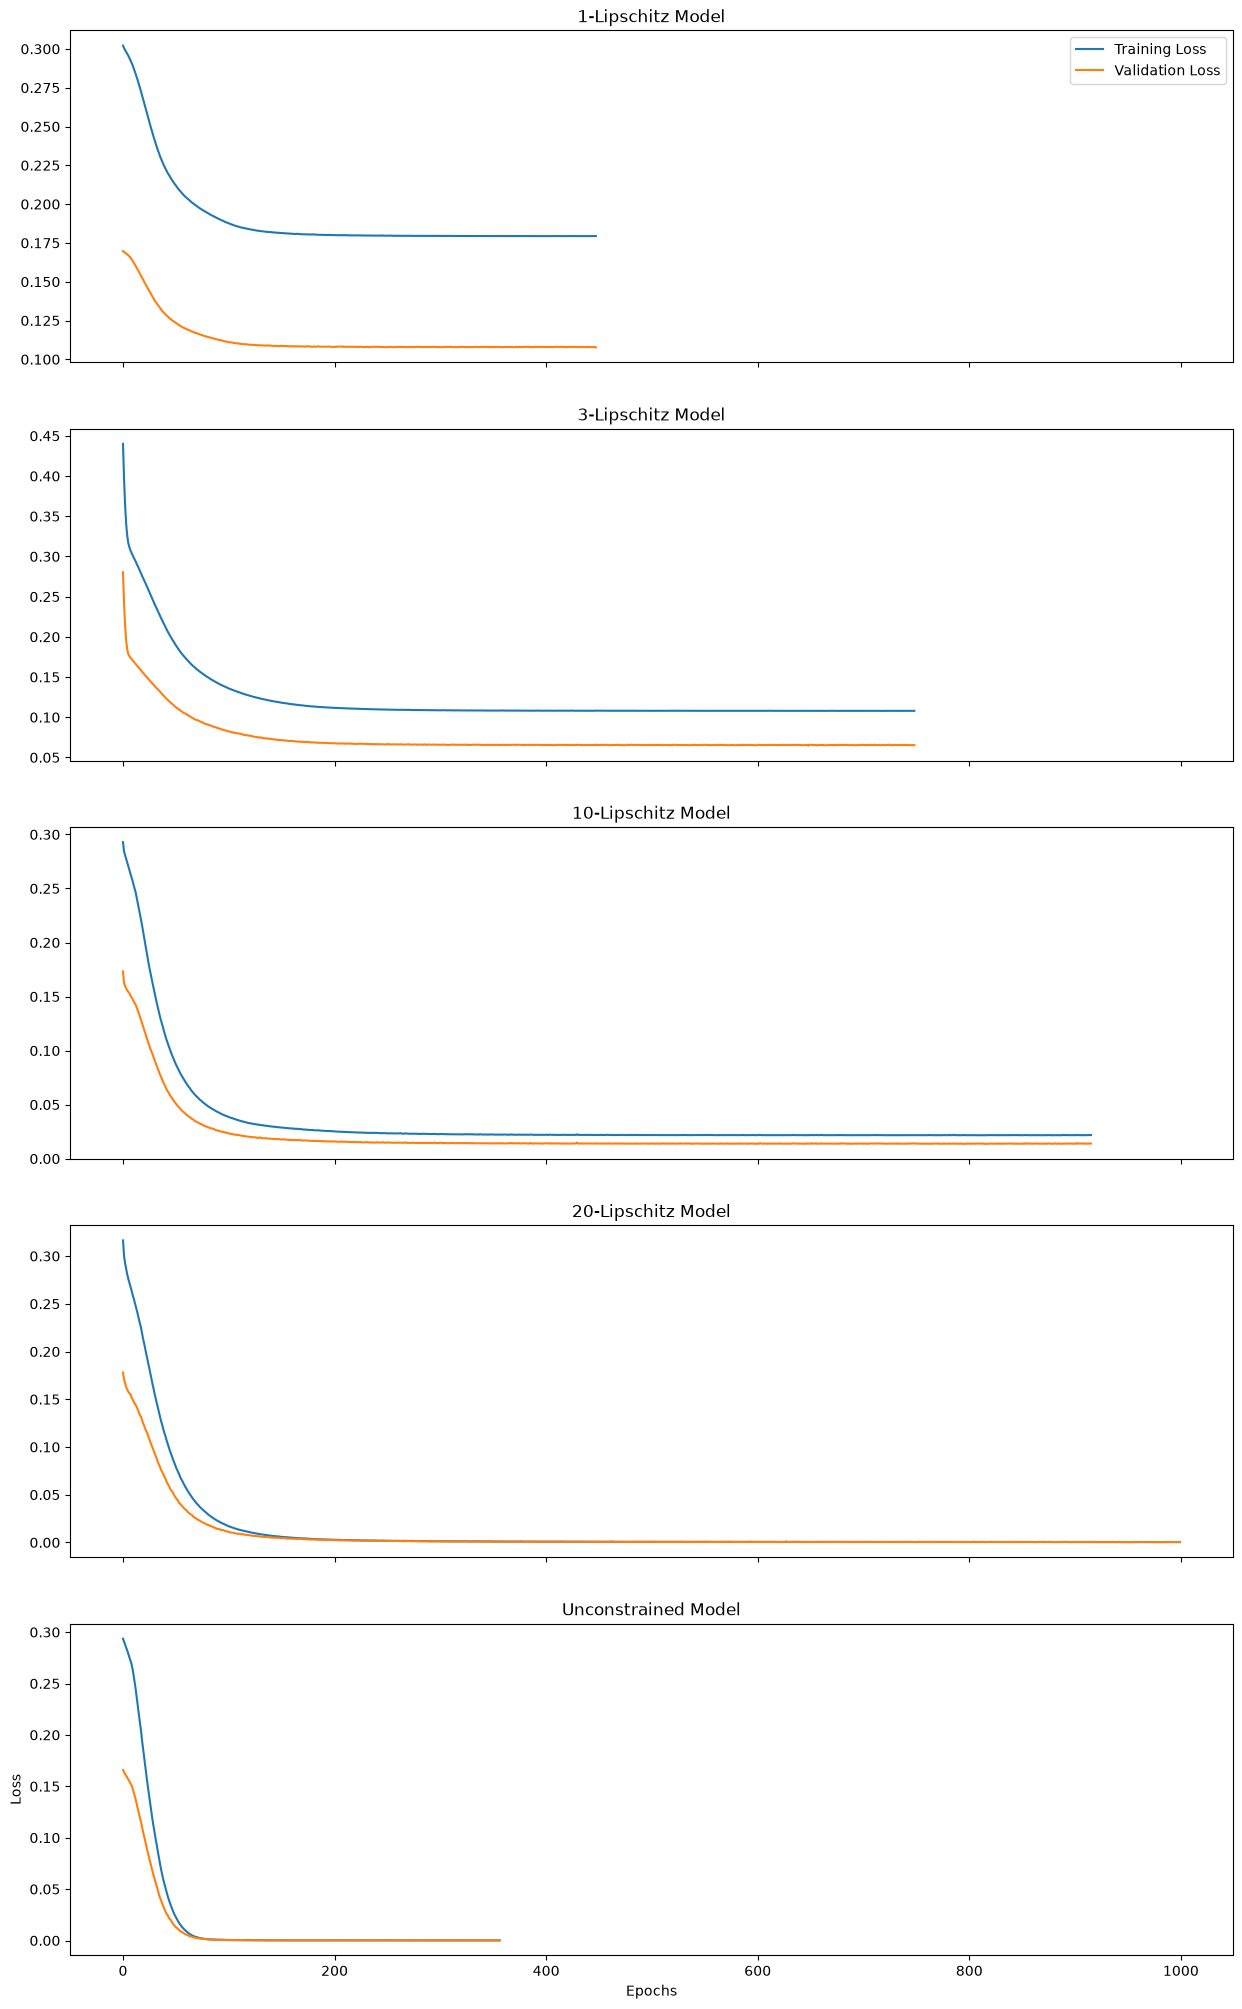

In [ ]:
# Check training losses
fig, axs = plt.subplots(5, 1, sharex=True, figsize=(15, 25))
axs[0].set_title("1-Lipschitz Model")
axs[0].plot(train_losses_L1, label='Training Loss')
axs[0].plot(val_losses_L1, label='Validation Loss')
axs[1].set_title("3-Lipschitz Model")
axs[1].plot(train_losses_L3, label='Training Loss (Lipschitz Model, L=3)')
axs[1].plot(val_losses_L3, label='Validation Loss (Lipschitz Model, L=3)')
axs[2].set_title("10-Lipschitz Model")
axs[2].plot(train_losses_L10, label='Training Loss (Lipschitz Model, L=10)')
axs[2].plot(val_losses_L10, label='Validation Loss (Lipschitz Model, L=10)')
axs[3].set_title("20-Lipschitz Model")
axs[3].plot(train_losses_L20, label='Training Loss (Lipschitz Model, L=20)')
axs[3].plot(val_losses_L20, label='Validation Loss (Lipschitz Model, L=20)')
axs[4].set_title("Unconstrained Model")
axs[4].plot(train_losses_unconstrained, label='Training Loss (Unconstrained Model)')
axs[4].plot(val_losses_unconstrained, label='Validation Loss (Unconstrained Model)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
axs[0].legend()
#axs[1].legend()
plt.show

In [ ]:
# Predictions
lipschitz_1_predictions = Lipschitz_1_model(x_gaussian_linspace).detach().numpy()
lipschitz_3_predictions = Lipschitz_3_model(x_gaussian_linspace).detach().numpy()
lipschitz_10_predictions = Lipschitz_10_model(x_gaussian_linspace).detach().numpy()
lipschitz_20_predictions = Lipschitz_20_model(x_gaussian_linspace).detach().numpy()
unconstrained_predictions = Unconstrained_model(x_gaussian_linspace).detach().numpy()

# Calculating Lipschitz constants for the trained models
lipschitz_constant_L1 = calculate_lipschitz_constant(Lipschitz_1_model, x_gaussian_linspace)
lipschitz_constant_L3 = calculate_lipschitz_constant(Lipschitz_3_model, x_gaussian_linspace)
lipschitz_constant_L10 = calculate_lipschitz_constant(Lipschitz_10_model, x_gaussian_linspace)
lipschitz_constant_L20 = calculate_lipschitz_constant(Lipschitz_20_model, x_gaussian_linspace)
lipschitz_constant_unconstrained = calculate_lipschitz_constant(Unconstrained_model, x_gaussian_linspace)
true_lipschitz_constant = gaussian_lipschitz_constant(SIGMA)


<>:4: SyntaxWarning: invalid escape sequence '\h'
<>:5: SyntaxWarning: invalid escape sequence '\h'
<>:6: SyntaxWarning: invalid escape sequence '\h'
<>:7: SyntaxWarning: invalid escape sequence '\h'
<>:8: SyntaxWarning: invalid escape sequence '\h'
<>:9: SyntaxWarning: invalid escape sequence '\h'
<>:4: SyntaxWarning: invalid escape sequence '\h'
<>:5: SyntaxWarning: invalid escape sequence '\h'
<>:6: SyntaxWarning: invalid escape sequence '\h'
<>:7: SyntaxWarning: invalid escape sequence '\h'
<>:8: SyntaxWarning: invalid escape sequence '\h'
<>:9: SyntaxWarning: invalid escape sequence '\h'
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_75468/3925405915.py:4: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(x_gaussian_linspace.numpy(), lipschitz_1_predictions, label=f'L=1, $\hat{{L}}$={lipschitz_constant_L1:.2f}', color='orange')
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_75468/3925405915.py:5: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(x

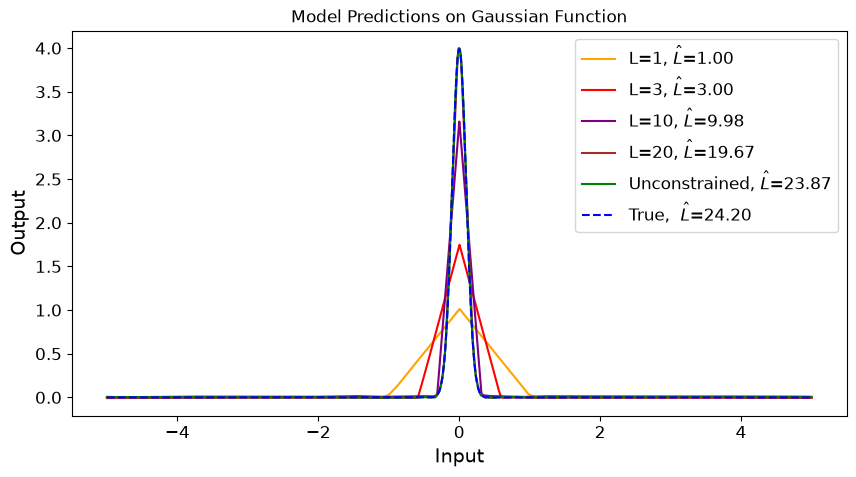

In [ ]:

# Plotting predictions
plt.figure(figsize=(10, 5))
#plt.plot(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), label='True Values', color='blue')
plt.plot(x_gaussian_linspace.numpy(), lipschitz_1_predictions, label=f'L=1, $\hat{{L}}$={lipschitz_constant_L1:.2f}', color='orange')
plt.plot(x_gaussian_linspace.numpy(), lipschitz_3_predictions, label=f'L=3, $\hat{{L}}$={lipschitz_constant_L3:.2f}', color='red')
plt.plot(x_gaussian_linspace.numpy(), lipschitz_10_predictions, label=f'L=10, $\hat{{L}}$={lipschitz_constant_L10:.2f}', color='purple')
plt.plot(x_gaussian_linspace.numpy(), lipschitz_20_predictions, label=f'L=20, $\hat{{L}}$={lipschitz_constant_L20:.2f}', color='brown')
plt.plot(x_gaussian_linspace.numpy(), unconstrained_predictions, label=f'Unconstrained, $\hat{{L}}$={lipschitz_constant_unconstrained:.2f}', color='green')
plt.plot(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), '--' , label=f'True,  $\hat{{L}}$={true_lipschitz_constant:.2f}', color='blue')
plt.xlabel('Input', fontsize=14)
plt.ylabel('Output', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.savefig('Plots/gaussian_narrow_fit.pdf')
plt.title('Model Predictions on Gaussian Function')
plt.show()

In [ ]:
# Area for the different predictions
lipschitz_1_area = np.trapezoid(lipschitz_1_predictions.flatten(), x_gaussian_linspace.flatten())
lipschitz_3_area = np.trapezoid(lipschitz_3_predictions.flatten(), x_gaussian_linspace.flatten())
lipschitz_10_area = np.trapezoid(lipschitz_10_predictions.flatten(), x_gaussian_linspace.flatten())
lipschitz_20_area = np.trapezoid(lipschitz_20_predictions.flatten(), x_gaussian_linspace.flatten())
unconstrained_area = np.trapezoid(unconstrained_predictions.flatten(), x_gaussian_linspace.flatten())
true_area = np.trapezoid(y_gaussian_linspace.flatten(), x_gaussian_linspace.flatten())

print(f"Area under the curve for L=1 model: {lipschitz_1_area:.4f}")
print(f"Area under the curve for L=3 model: {lipschitz_3_area:.4f}")
print(f"Area under the curve for L=10 model: {lipschitz_10_area:.4f}")
print(f"Area under the curve for L=20 model: {lipschitz_20_area:.4f}")
print(f"Area under the curve for Unconstrained model: {unconstrained_area:.4f}")
print(f"Area under the curve for True Gaussian function: {true_area:.4f}")

Area under the curve for L=1 model: 1.0431
Area under the curve for L=3 model: 1.0049
Area under the curve for L=10 model: 1.0944
Area under the curve for L=20 model: 0.9785
Area under the curve for Unconstrained model: 1.0325
Area under the curve for True Gaussian function: 1.0000


In [36]:
# The cost of the different Lipschitz constants
# Compute the best possible Lipschitz fit for the different L, and compare the errors and the FWHM of the different fits. 
from lipschitz_floor import lipschitz_floor_scan
# Making a gaussian
N = 2000
MU = 0
SIGMA = 2
NOISE_MAGNITUDE = 0.01

x_gaussian_train, y_gaussian_train, x_gaussian_linspace, y_gaussian_linspace = gaussian_function_data(N=N, mu=MU, sigma=SIGMA, noise_magnitude=NOISE_MAGNITUDE)

# Scan of L values
L_true = gaussian_lipschitz_constant(SIGMA)
print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {L_true:.4f}")
L_scan = np.logspace(np.log10(0.01 * L_true), np.log10(2 * L_true), 40)

# Calculating the floor functions
#L_floors, MSE_floors, gaps = [], [], []
#x_np, y_np = x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy()
#for L in L_scan:
#    L, MSE, gap = lipschitz_floor_1D(x_np, y_np, L)
#    L_floors.append(L)
#    MSE_floors.append(MSE)
#    gaps.append(gap)

MSE_floors = lipschitz_floor_scan(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), L_scan)


Lipschitz constant of the Gaussian function with sigma=2: 0.0605


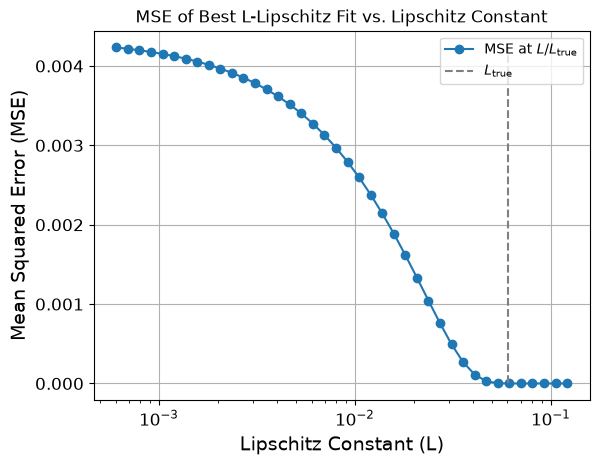

In [39]:
plt.plot(L_scan, MSE_floors, '-o', label='MSE at $L/L_{\\text{true}}$')
plt.vlines(L_true, ymin=min(MSE_floors), ymax=max(MSE_floors), colors='grey', linestyles='dashed', label='$L_{\\text{true}}$')
plt.xscale('log')
plt.xlabel('Lipschitz Constant (L)', fontsize=14)
plt.ylabel('Mean Squared Error (MSE)', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
plt.title('MSE of Best L-Lipschitz Fit vs. Lipschitz Constant')
plt.legend()
#plt.savefig('Plots/gaussian_lipschitz_floor.pdf')
plt.show()

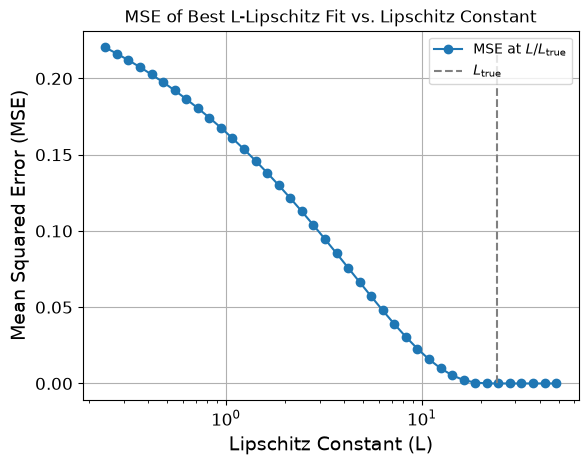

In [ ]:
plt.plot(L_scan, MSE_floors, '-o', label='MSE at $L/L_{\\text{true}}$')
plt.vlines(L_true, ymin=min(MSE_floors), ymax=max(MSE_floors), colors='grey', linestyles='dashed', label='$L_{\\text{true}}$')
plt.xscale('log')
plt.xlabel('Lipschitz Constant (L)', fontsize=14)
plt.ylabel('Mean Squared Error (MSE)', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
plt.title('MSE of Best L-Lipschitz Fit vs. Lipschitz Constant')
plt.legend()
#plt.savefig('Plots/gaussian_lipschitz_floor.pdf')
plt.show()

In [ ]:
# Evolution of the FWHM of the the floor function related to the true
FWHM_true = FWHM_calculation(x_gaussian_linspace.detach().numpy(), y_gaussian_linspace.detach().numpy())
print(f"FWHM of the true Gaussian function: {FWHM_true.item():.4f}")

FWHM_floors = [FWHM_calculation(x_floor_linspace.detach().numpy(), y_floor_linspace.detach().numpy())]

FWHM of the true Gaussian function: 0.2326


In [ ]:
# The cost of the different Lipschitz constants
# For a range of L we compute the floor (best possible L-Lipschitz fit) and measure how much error the constraint
# alone forces on ANY L-Lipschitz model. No training is needed for the curves, the trained networks are added as points.
# Every panel is saved as its own pdf, sized for three side by side in the report (subfigures of 0.32\textwidth).



def to_numpy(a):
    return (a.detach().numpy() if torch.is_tensor(a) else np.asarray(a)).ravel()

def guaranteed_max_error(x, f, L):
    """
    Smallest possible worst-case error max|g - f| over ALL L-Lipschitz functions g (exact, closed form).
    If two points are steeper apart than L allows, f(y) - f(x) - L|y - x| = 2*eps > 0, then any L-Lipschitz g
    must miss f by at least eps at one of them. The best g reaches exactly half of the largest such violation.
    """
    order = np.argsort(x)
    x, f = x[order], f[order]
    rise = f - L * x  # violations going up:   (f_j - L x_j) - (f_i - L x_i) for i < j
    fall = f + L * x  # violations going down: (f_i + L x_i) - (f_j + L x_j) for i < j
    worst_up = np.max(rise - np.minimum.accumulate(rise))
    worst_down = np.max(np.maximum.accumulate(fall) - fall)
    return 0.5 * max(worst_up, worst_down, 0.0)


x_np = to_numpy(x_gaussian_linspace)
f_np = to_numpy(y_gaussian_linspace)
L_true = gaussian_lipschitz_constant(SIGMA)
peak_region = np.abs(x_np - MU) < 3 * SIGMA
peak_true = f_np.max()

# Scan of Lipschitz constants, from far too small to larger than needed
L_scan = np.logspace(np.log10(0.02 * L_true), np.log10(2 * L_true), 20)


def relative_mse_peak(g):
    return np.mean((g - f_np)[peak_region] ** 2) / np.mean(f_np[peak_region] ** 2)


rel_mse_peak = np.array([relative_mse_peak(lipschitz_floor(x_np, f_np, L)[0]) for L in L_scan])
sup_error = np.array([guaranteed_max_error(x_np, f_np, L) / peak_true for L in L_scan])

# Floor fits for the L values we plot and tabulate (the trained networks use L = 1, 3, 10, 20)
L_show = [L for L in [1, 3, 10, 20] if L < L_true]  # for L >= L_true the floor is the truth itself
floors = {L: lipschitz_floor(x_np, f_np, L)[0] for L in L_show}

# Trained networks (only the ones that exist in the notebook)
trained = {L: globals()[name] for L, name in [(1, "lipschitz_1_predictions"), (3, "lipschitz_3_predictions"),
                                              (10, "lipschitz_10_predictions"), (20, "lipschitz_20_predictions")]
           if name in globals()}
net_rel_mse = {L: relative_mse_peak(to_numpy(p)) for L, p in trained.items()}
net_sup = {L: np.max(np.abs(to_numpy(p) - f_np)) / peak_true for L, p in trained.items()}

# Zoom to where the floors differ visibly from the truth (but stay inside the fitted range)
differs = np.any([np.abs(g - f_np) > 0.01 * peak_true for g in floors.values()], axis=0)
half_width = 1.15 * np.abs(x_np[differs] - MU).max() if differs.any() else 4 * SIGMA
x_lo, x_hi = max(x_np.min(), MU - half_width), min(x_np.max(), MU + half_width)


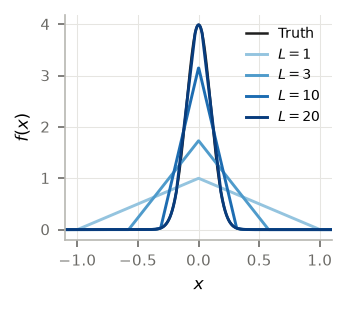

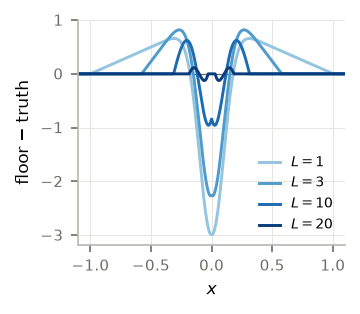

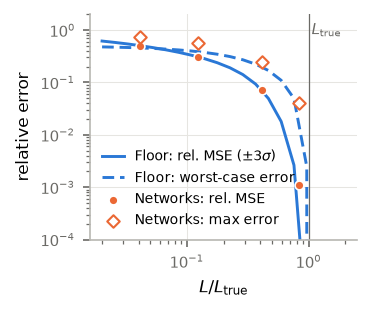

      L  L/L_true  rel. MSE ±3σ  worst-case err/peak  floor peak/true
    1.0      0.04        0.5042               0.4572            0.250
    3.0      0.12        0.3071               0.3869            0.433
   10.0      0.41        0.0707               0.1979            0.789
   20.0      0.83        0.0008               0.0298            1.000


In [ ]:

# --- Figures for the report
C_TRUE, C_FLOOR, C_NET, C_MUTED = "#1f1f1f", "#2a78d6", "#eb6834", "#6b6a66"
shades = plt.cm.Blues(np.linspace(0.4, 0.95, len(L_show)))  # one hue, light -> dark = small -> large L

PANEL_SIZE = (2.3, 1.95)  # inches, close to the final size of a 0.32\textwidth subfigure, so the fonts stay readable
REPORT_STYLE = {
    "font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b8b7b2",
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.5, "axes.axisbelow": True,
    "legend.frameon": False, "legend.handlelength": 1.6, "figure.dpi": 150, "savefig.bbox": "tight",
}

with plt.rc_context(REPORT_STYLE):
    # (a) What the floor looks like for different L
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    ax.plot(x_np, f_np, color=C_TRUE, lw=1.2, label="Truth")
    for L, c in zip(L_show, shades):
        ax.plot(x_np, floors[L], color=c, lw=1.4, label=rf"$L = {L:g}$")
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$f(x)$")
    ax.legend(loc="upper right")
    fig.savefig("Plots/gaussian_cost_floor_fits.pdf")
    plt.show()

    # (b) Where the error lives: signed bias of the floor
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    ax.axhline(0, color=C_MUTED, lw=0.6)
    for L, c in zip(L_show, shades):
        ax.plot(x_np, floors[L] - f_np, color=c, lw=1.4, label=rf"$L = {L:g}$")
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel(r"$x$"); ax.set_ylabel("floor − truth")
    ax.legend(loc="lower right")
    fig.savefig("Plots/gaussian_cost_floor_bias.pdf")
    plt.show()

    # (c) The cost as a function of L
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    r = L_scan / L_true
    ax.plot(r, rel_mse_peak, color=C_FLOOR, lw=1.4, label=r"Floor: rel. MSE ($\pm3\sigma$)")
    ax.plot(r, sup_error, color=C_FLOOR, lw=1.4, ls=(0, (4, 2)), label="Floor: worst-case error")
    if trained:
        ax.scatter([L / L_true for L in net_rel_mse], list(net_rel_mse.values()), s=18, color=C_NET, zorder=3,
                   edgecolor="white", linewidth=0.8, label="Networks: rel. MSE")
        ax.scatter([L / L_true for L in net_sup], list(net_sup.values()), s=18, marker="D", facecolor="white",
                   edgecolor=C_NET, linewidth=1.0, zorder=3, label="Networks: max error")
    ax.axvline(1, color=C_MUTED, lw=0.6)
    ax.text(1.06, 0.96, r"$L_\mathrm{true}$", transform=ax.get_xaxis_transform(), va="top", fontsize=7,
            color=C_MUTED)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_ylim(1e-4, 2)
    ax.set_xlabel(r"$L / L_\mathrm{true}$"); ax.set_ylabel("relative error")
    ax.legend(loc="lower left")
    fig.savefig("Plots/gaussian_cost_vs_L.pdf")
    plt.show()

# --- Table
print(f"{'L':>7} {'L/L_true':>9} {'rel. MSE ±3σ':>13} {'worst-case err/peak':>20} {'floor peak/true':>16}")
for L in L_show:
    g = floors[L]
    print(f"{L:7.1f} {L / L_true:9.2f} {relative_mse_peak(g):13.4f} "
          f"{guaranteed_max_error(x_np, f_np, L) / peak_true:20.4f} {g.max() / peak_true:16.3f}")

/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_75468/2585539575.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  lipschitz_1_errors = y_gaussian_linspace - lipschitz_1_predictions
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_75468/2585539575.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  lipschitz_3_errors = y_gaussian_linspace - lipschitz_3_predictions
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_75468/2585539575.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  unconstrained_errors = y_gaussian_linspace - unconstrained_predictions
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_75468/2585539575.py:6: DeprecationWarning: __array_wrap__ must accept contex

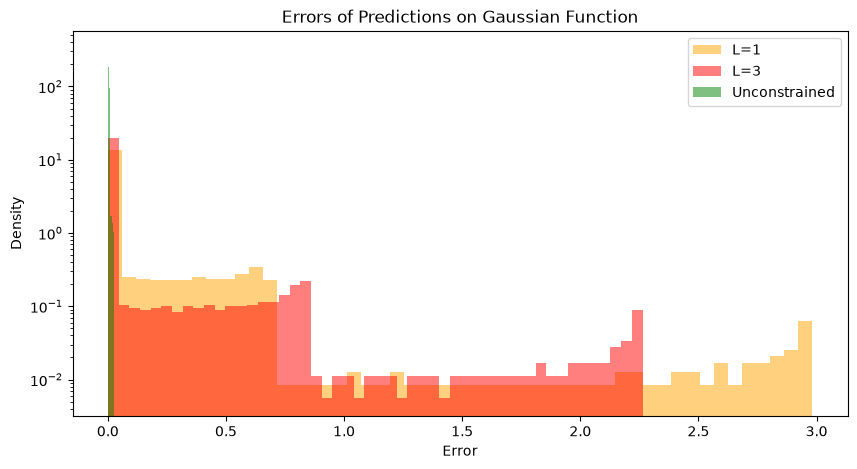

In [ ]:
# Errors
lipschitz_1_errors = y_gaussian_linspace - lipschitz_1_predictions
lipschitz_3_errors = y_gaussian_linspace - lipschitz_3_predictions
unconstrained_errors = y_gaussian_linspace - unconstrained_predictions

abs_errors_L1 = np.abs(lipschitz_1_errors)
abs_errors_L3 = np.abs(lipschitz_3_errors)
abs_errors_unconstrained = np.abs(unconstrained_errors)

plt.figure(figsize=(10, 5))
plt.hist(abs_errors_L1, bins=50, alpha=0.5, label='L=1', color='orange', density=True)
plt.hist(abs_errors_L3, bins=50, alpha=0.5, label='L=3', color='red', density=True)
plt.hist(abs_errors_unconstrained, bins=50, alpha=0.5, label='Unconstrained', color='green', density=True)
plt.title('Errors of Predictions on Gaussian Function')
plt.xlabel('Error')
plt.ylabel('Density')
plt.yscale('log')
plt.legend()
plt.show()

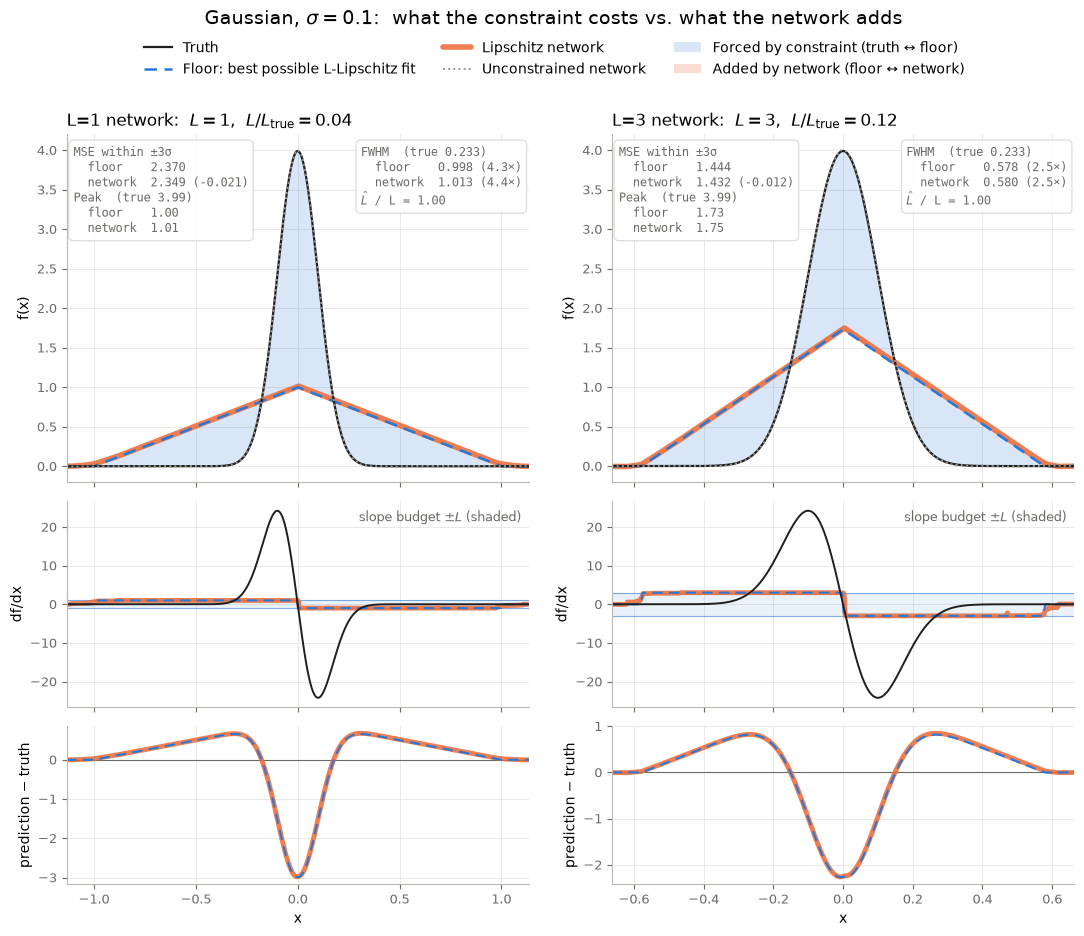

In [ ]:
# Computing the floor and comparing it to the trained networks
# One pdf per network (truth, floor, network | slope | residuals), sized for two side by side in the report
# (subfigures of 0.48\textwidth).
from lipschitz_floor import lipschitz_floor

# Colours (validated categorical palette, slot 1 & 2) + neutral inks
C_TRUE, C_FLOOR, C_NET, C_REF, C_MUTED = "#1f1f1f", "#2a78d6", "#eb6834", "#9a9893", "#6b6a66"

COLUMN_SIZE = (3.1, 4.1)  # inches, close to the final size of a 0.48\textwidth subfigure
REPORT_STYLE = {
    "font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b8b7b2",
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.5, "axes.axisbelow": True,
    "legend.frameon": False, "legend.handlelength": 1.8, "figure.dpi": 150, "savefig.bbox": "tight",
}


def network_slope(model, x):
    """df/dx of the network at every point of x (shape (n, 1)), via autograd."""
    x = x.clone().detach().requires_grad_(True)
    grad, = torch.autograd.grad(model(x).sum(), x)
    return grad.detach().numpy().ravel()


def fwhm(x, f):
    """Full width at half maximum of a single peak on a zero baseline."""
    above = x[f >= 0.5 * f.max()]
    return above.max() - above.min()


def plot_floor_comparison(x, y_true, lipschitz_models, sigma, mu=0.0, reference_model=None, save_prefix=None,
                          show_metrics=True):
    """
    One figure per Lipschitz model, with three rows:
      1) the fit: truth, best possible L-Lipschitz fit (floor), network. Shaded areas split the error into
         the part the constraint forces (truth <-> floor) and the part the network adds (floor <-> network).
      2) the slope: truth, floor and network slope against the slope budget [-L, L]
      3) the residuals (prediction - truth) for the floor and the network
    Each figure is saved as f"{save_prefix}_L{L}.pdf".
    """
    x_np = x.detach().numpy().ravel()
    y_np = y_true.detach().numpy().ravel()
    slope_true = np.gradient(y_np, x_np)
    peak_region = np.abs(x_np - mu) < 3 * sigma

    ref_pred = None
    if reference_model is not None:
        with torch.no_grad():
            ref_pred = reference_model(x).numpy().ravel()

    summary = []
    for name, model in lipschitz_models.items():
        L = float(model.lipschitz_bound)
        with torch.no_grad():
            pred = model(x).numpy().ravel()
        slope_net = network_slope(model, x)
        floor_fit, _ = lipschitz_floor(x_np, y_np, L)
        slope_floor = np.gradient(floor_fit, x_np)

        # Metrics in the peak region (the tails are flat and would hide everything)
        mse_floor = np.mean((floor_fit - y_np)[peak_region] ** 2)
        mse_net = np.mean((pred - y_np)[peak_region] ** 2)
        L_hat = np.abs(slope_net).max()
        width_true, width_floor, width_net = fwhm(x_np, y_np), fwhm(x_np, floor_fit), fwhm(x_np, pred)
        summary.append(dict(name=name, L=L, mse_floor=mse_floor, mse_net=mse_net,
                            peak_true=y_np.max(), peak_floor=floor_fit.max(), peak_net=pred.max(),
                            fwhm_true=width_true, fwhm_floor=width_floor, fwhm_net=width_net, L_hat=L_hat))

        # Zoom: wherever the floor or the network differs visibly from the truth, at least +-4 sigma
        differs = np.maximum(np.abs(floor_fit - y_np), np.abs(pred - y_np)) > 0.01 * y_np.max()
        half_width = max(4 * sigma, 1.15 * np.abs(x_np[differs] - mu).max()) if differs.any() else 4 * sigma
        lo, hi = max(x_np.min(), mu - half_width), min(x_np.max(), mu + half_width)

        with plt.rc_context(REPORT_STYLE):
            fig, axs = plt.subplots(3, 1, figsize=COLUMN_SIZE, sharex=True,
                                    gridspec_kw=dict(height_ratios=[2.2, 1.3, 1.0], hspace=0.1))

            # --- Row 1: the fit
            ax = axs[0]
            ax.fill_between(x_np, y_np, floor_fit, color=C_FLOOR, alpha=0.18, lw=0, label="Forced by constraint")
            ax.fill_between(x_np, floor_fit, pred, color=C_NET, alpha=0.22, lw=0, label="Added by network")
            # The network is drawn wide and underneath, so the dashed floor stays visible when they overlap
            ax.plot(x_np, pred, color=C_NET, lw=2.6, alpha=0.85, solid_capstyle="round", label="Lipschitz network")
            ax.plot(x_np, floor_fit, color=C_FLOOR, lw=1.2, ls=(0, (4, 2)), label="Floor")
            ax.plot(x_np, y_np, color=C_TRUE, lw=1.0, label="Truth")
            if ref_pred is not None:
                ax.plot(x_np, ref_pred, color=C_REF, lw=1.0, ls=":", label="Unconstrained network")
            if show_metrics:
                box = dict(va="top", fontsize=5.5, family="monospace", color=C_MUTED, transform=ax.transAxes,
                           bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#dddcd8", lw=0.5, alpha=0.9))
                ax.text(0.02, 0.97,
                        f"Peak  (true {y_np.max():.2f})\n"
                        f" floor    {floor_fit.max():.2f}\n"
                        f" network  {pred.max():.2f}", ha="left", **box)
                ax.text(0.98, 0.97,
                        f"FWHM  (true {width_true:.3f})\n"
                        f" floor    {width_floor:.3f}\n"
                        f" network  {width_net:.3f}", ha="right", multialignment="left", **box)
            ax.set_ylabel(r"$f(x)$")

            # --- Row 2: the slope against the slope budget
            ax = axs[1]
            ax.axhspan(-L, L, color=C_FLOOR, alpha=0.10, lw=0)
            ax.axhline(L, color=C_FLOOR, lw=0.5, alpha=0.6)
            ax.axhline(-L, color=C_FLOOR, lw=0.5, alpha=0.6)
            ax.plot(x_np, slope_net, color=C_NET, lw=2.2, alpha=0.85)
            ax.plot(x_np, slope_floor, color=C_FLOOR, lw=1.0, ls=(0, (4, 2)))
            ax.plot(x_np, slope_true, color=C_TRUE, lw=0.9)
            ax.text(0.98, 0.93, r"slope budget $\pm L$ (shaded)", transform=ax.transAxes, ha="right", va="top",
                    fontsize=6, color=C_MUTED)
            ax.set_ylabel(r"$\mathrm{d}f/\mathrm{d}x$")

            # --- Row 3: residuals
            ax = axs[2]
            ax.axhline(0, color=C_MUTED, lw=0.5)
            ax.plot(x_np, pred - y_np, color=C_NET, lw=2.2, alpha=0.85)
            ax.plot(x_np, floor_fit - y_np, color=C_FLOOR, lw=1.0, ls=(0, (4, 2)))
            ax.set_ylabel("pred. − truth")
            ax.set_xlabel(r"$x$")
            ax.set_xlim(lo, hi)
            fig.align_ylabels(axs)

            handles, labels = axs[0].get_legend_handles_labels()
            order = ["Truth", "Floor", "Lipschitz network", "Unconstrained network",
                     "Forced by constraint", "Added by network"]
            by_label = dict(zip(labels, handles))
            order = [label for label in order if label in by_label]
            fig.legend([by_label[label] for label in order], order, loc="lower center", ncol=2,
                       bbox_to_anchor=(0.5, 0.885), columnspacing=1.2)
            fig.subplots_adjust(top=0.87)
            if save_prefix is not None:
                fig.savefig(f"{save_prefix}_L{L:g}.pdf")
            print(f"{name}: L = {L:g}, L/L_true = {L / np.abs(slope_true).max():.2f}, "
                  f"MSE within ±3σ: floor {mse_floor:.3f}, network {mse_net:.3f}, L_hat/L = {L_hat / L:.2f}")
            plt.show()
    return summary


summary = plot_floor_comparison(
    x_gaussian_linspace, y_gaussian_linspace,
    lipschitz_models={"L=1 network": Lipschitz_1_model, "L=3 network": Lipschitz_3_model},
    sigma=SIGMA, mu=MU,
    reference_model=Unconstrained_model,
    save_prefix="Plots/gaussian_floor_comparison",
)

# Sine-noise testing
Similar to the ''Spectral Bias'' paper, we can test the fourier spectrum of the learned function vs the target function separates the fourier modes. Hypothesis: the Lipschitz constraint will limit high frequency modes similar to the suggested clipping of fourier modes in the paper. Ideally, it will act as a low pass filter for sine waves $\sin(\omega x)$ for $\omega > L$.

**Setup.** A wide Gaussian ($\sigma = 2$, unit area) plus three sine modes $A\sin(\omega_n x)$ with $A = 0.1$ and known frequencies. A mode needs a slope of $A\omega$, so the refined hypothesis is that an $L$-Lipschitz model suppresses modes with $A\omega \gtrsim L$, i.e. a cutoff $\omega_c \approx L/A$. The cutoff depends on the amplitude, and the filter is not linear: clipping the slope can move part of a mode into other frequencies (harmonics).

To separate the effect of the Lipschitz bound from spectral bias, we compare against
- an unconstrained network of the same size, which must be able to fit all modes (otherwise the test says nothing about the bound),
- the floor fitted to the same noisy data: the ideal $L$-Lipschitz filter, without any training.

Networks: $L \in \{0.25, 0.5, 1, 2\}$, 3 seeds each, width 64, depth 5, full-batch Adam. Runtime about 5 minutes.

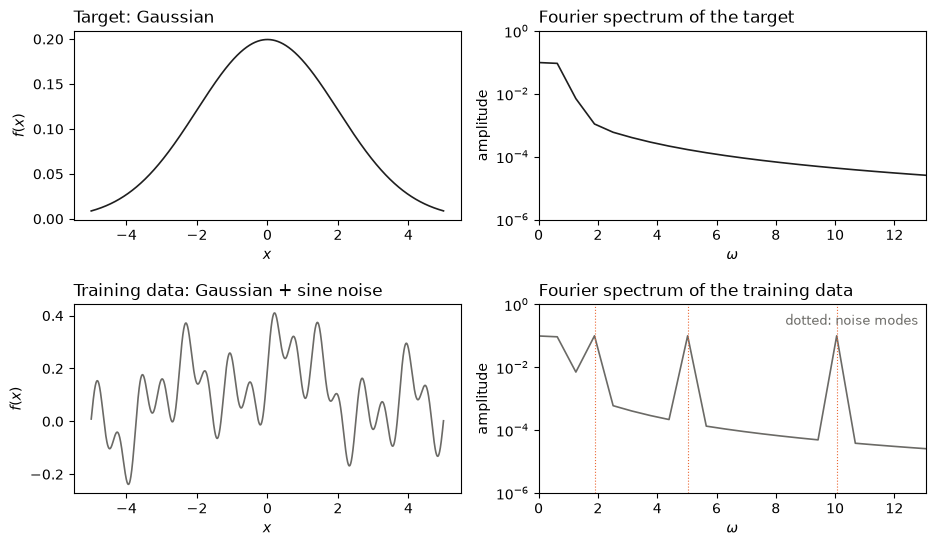

Noise modes and the slope they need (A * omega):
  omega =  1.88   A*omega = 0.19
  omega =  5.03   A*omega = 0.50
  omega = 10.05   A*omega = 1.01
Slope of the Gaussian itself: 0.06


In [21]:
# Target, noisy data and their Fourier spectra
X_RANGE = (-5, 5)
N_POINTS = 2000
SIGMA_TARGET = 2.0  # wide Gaussian: its own slope (max 0.06) uses only a small part of the slope budget,
                    # and its spectrum (width ~1/sigma) stays clear of the noise modes

# Sine "noise" with known frequencies. omega_n = 2*pi*n / (range length) puts every mode exactly on an FFT bin.
NOISE_AMPLITUDE = 0.1
NOISE_MODES = [3, 8, 16]  # low enough that an unconstrained network can fit all of them (checked below)
x_length = X_RANGE[1] - X_RANGE[0]
noise_omegas = [2 * np.pi * n / x_length for n in NOISE_MODES]

x_grid = np.linspace(X_RANGE[0], X_RANGE[1], N_POINTS, endpoint=False)  # periodic grid, no double end point
target = np.exp(-x_grid**2 / (2 * SIGMA_TARGET**2)) / (SIGMA_TARGET * np.sqrt(2 * np.pi))
noise = sum(NOISE_AMPLITUDE * np.sin(w * x_grid) for w in noise_omegas)
noisy = target + noise


def fourier_spectrum(f, x):
    """Amplitude of each sine/cosine mode: a term A sin(omega x) shows up as a peak of height A at omega."""
    amplitude = 2 * np.abs(np.fft.rfft(f)) / len(f)
    amplitude[0] /= 2  # the constant term is not doubled
    omega = 2 * np.pi * np.fft.rfftfreq(len(f), d=x[1] - x[0])
    return omega, amplitude


OMEGA_MAX = 1.3 * max(noise_omegas)  # nothing interesting happens above the highest noise mode


def plot_function_and_spectrum(axs, f, label, color, ls="-"):
    omega, amp = fourier_spectrum(f, x_grid)
    axs[0].plot(x_grid, f, color=color, lw=1.2, ls=ls, label=label)
    axs[1].plot(omega, amp, color=color, lw=1.2, ls=ls, label=label)
    axs[1].set_yscale("log"); axs[1].set_ylim(1e-6, 1)
    axs[1].set_xlim(0, OMEGA_MAX)
    axs[0].set_xlabel(r"$x$"); axs[0].set_ylabel(r"$f(x)$")
    axs[1].set_xlabel(r"$\omega$"); axs[1].set_ylabel("amplitude")


fig, axs = plt.subplots(2, 2, figsize=(11, 6), gridspec_kw=dict(hspace=0.45))
plot_function_and_spectrum(axs[0], target, "Target", "#1f1f1f")
axs[0, 0].set_title("Target: Gaussian", loc="left")
axs[0, 1].set_title("Fourier spectrum of the target", loc="left")
plot_function_and_spectrum(axs[1], noisy, "Target + sine noise", "#6b6a66")
axs[1, 0].set_title("Training data: Gaussian + sine noise", loc="left")
axs[1, 1].set_title("Fourier spectrum of the training data", loc="left")
for w in noise_omegas:
    axs[1, 1].axvline(w, color="#eb6834", lw=0.8, ls=":")
axs[1, 1].text(0.98, 0.95, "dotted: noise modes", transform=axs[1, 1].transAxes, ha="right", va="top",
               fontsize=9, color="#6b6a66")
plt.show()

print("Noise modes and the slope they need (A * omega):")
for n, w in zip(NOISE_MODES, noise_omegas):
    print(f"  omega = {w:5.2f}   A*omega = {NOISE_AMPLITUDE * w:.2f}")
print(f"Slope of the Gaussian itself: {gaussian_lipschitz_constant(SIGMA_TARGET):.2f}")

In [22]:
from lipschitz_floor import lipschitz_floor

# Train Lipschitz networks with different L (several seeds each) and an unconstrained reference on the noisy data
L_VALUES = [0.25, 0.5, 1.0, 2.0]  # chosen so the predicted cutoff A*omega = L falls across the three noise modes
SEEDS = [0, 1, 2]
HIDDEN_DIM_NOISE = 64  # wider than before: the unconstrained network must be able to fit every noise mode, otherwise
N_GROUPS_NOISE = 8     # we cannot tell filtering by the Lipschitz bound apart from spectral bias / lack of capacity
DEPTH_NOISE = 5
STEPS = 6000           # full-batch training steps
LR = 3e-3

x_tensor = torch.tensor(x_grid, dtype=torch.float32).unsqueeze(-1)
y_noisy_tensor = torch.tensor(noisy, dtype=torch.float32).unsqueeze(-1)


def fit_network(model, x, y, steps=STEPS, lr=LR):
    """Plain full-batch training with Adam and MSE. Returns the trained model."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = ((model(x) - y) ** 2).mean()
        loss.backward()
        optimizer.step()
        scheduler.step()
    return model


predictions = {}  # predictions[L][seed] = network output on x_grid (L = None for the unconstrained network)
for L in L_VALUES + [None]:
    predictions[L] = {}
    for seed in SEEDS:
        torch.manual_seed(seed)
        if L is None:
            model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM_NOISE, output_dim=1, depth=DEPTH_NOISE)
        else:
            model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM_NOISE, output_dim=1, n_groups=N_GROUPS_NOISE,
                                   depth=DEPTH_NOISE, lipschitz_bound=L)
        fit_network(model, x_tensor, y_noisy_tensor)
        with torch.no_grad():
            predictions[L][seed] = model(x_tensor).numpy().ravel()
        print(f"L = {L}, seed {seed}: MSE to noisy data {np.mean((predictions[L][seed] - noisy)**2):.2e}")

# The ideal L-Lipschitz filter: the floor fitted to the same noisy data (no training involved)
floor_noisy = {L: lipschitz_floor(x_grid, noisy, L)[0] for L in L_VALUES}

L = 0.25, seed 0: MSE to noisy data 6.14e-03
L = 0.25, seed 1: MSE to noisy data 6.18e-03
L = 0.25, seed 2: MSE to noisy data 6.18e-03
L = 0.5, seed 0: MSE to noisy data 2.78e-03
L = 0.5, seed 1: MSE to noisy data 3.10e-03
L = 0.5, seed 2: MSE to noisy data 2.94e-03
L = 1.0, seed 0: MSE to noisy data 5.16e-04
L = 1.0, seed 1: MSE to noisy data 1.13e-03
L = 1.0, seed 2: MSE to noisy data 6.55e-04
L = 2.0, seed 0: MSE to noisy data 3.02e-04
L = 2.0, seed 1: MSE to noisy data 2.19e-04
L = 2.0, seed 2: MSE to noisy data 3.43e-04
L = None, seed 0: MSE to noisy data 4.62e-05
L = None, seed 1: MSE to noisy data 3.35e-04
L = None, seed 2: MSE to noisy data 1.82e-05


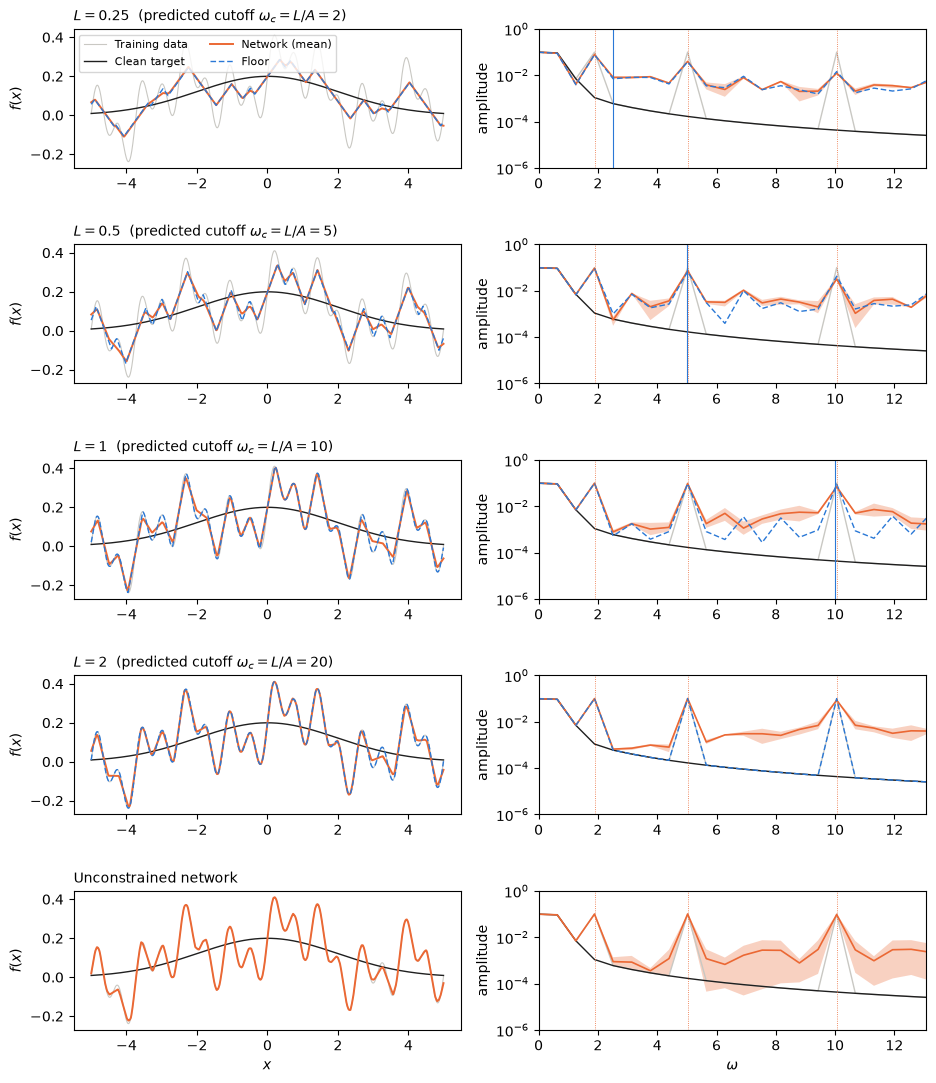

In [23]:
# Learned functions and their spectra: one row per L, mean over seeds with the min-max band
fig, axs = plt.subplots(len(L_VALUES) + 1, 2, figsize=(11, 2.6 * (len(L_VALUES) + 1)),
                        gridspec_kw=dict(hspace=0.55))
omega, amp_noisy = fourier_spectrum(noisy, x_grid)
_, amp_target = fourier_spectrum(target, x_grid)

for row, L in enumerate(L_VALUES + [None]):
    ax_f, ax_s = axs[row]
    preds = np.array([predictions[L][s] for s in SEEDS])
    spectra = np.array([fourier_spectrum(p, x_grid)[1] for p in preds])

    # Function: noisy data in grey, network (mean over seeds) in orange, floor dashed
    ax_f.plot(x_grid, noisy, color="#c9c8c3", lw=0.8, label="Training data")
    ax_f.plot(x_grid, target, color="#1f1f1f", lw=1.0, label="Clean target")
    ax_f.plot(x_grid, preds.mean(0), color="#eb6834", lw=1.4, label="Network (mean)")
    if L is not None:
        ax_f.plot(x_grid, floor_noisy[L], color="#2a78d6", lw=1.0, ls=(0, (4, 2)), label="Floor")

    # Spectrum: same colours, seed spread as a band
    ax_s.plot(omega, amp_noisy, color="#c9c8c3", lw=1.0)
    ax_s.plot(omega, amp_target, color="#1f1f1f", lw=1.0)
    ax_s.fill_between(omega, spectra.min(0), spectra.max(0), color="#eb6834", alpha=0.3, lw=0)
    ax_s.plot(omega, spectra.mean(0), color="#eb6834", lw=1.2)
    if L is not None:
        ax_s.plot(omega, fourier_spectrum(floor_noisy[L], x_grid)[1], color="#2a78d6", lw=1.0, ls=(0, (4, 2)))
        if L / NOISE_AMPLITUDE < OMEGA_MAX:
            ax_s.axvline(L / NOISE_AMPLITUDE, color="#2a78d6", lw=0.8)  # predicted cutoff A * omega = L
    for w in noise_omegas:
        ax_s.axvline(w, color="#eb6834", lw=0.6, ls=":")
    ax_s.set_yscale("log"); ax_s.set_ylim(1e-6, 1); ax_s.set_xlim(0, OMEGA_MAX)

    title = "Unconstrained network" if L is None else rf"$L = {L:g}$  (predicted cutoff $\omega_c = L/A = {L / NOISE_AMPLITUDE:.0f}$)"
    ax_f.set_title(title, loc="left", fontsize=10)
    ax_f.set_ylabel(r"$f(x)$"); ax_s.set_ylabel("amplitude")

axs[0, 0].legend(fontsize=8, ncol=2, loc="upper left")
axs[-1, 0].set_xlabel(r"$x$"); axs[-1, 1].set_xlabel(r"$\omega$")
plt.show()

Fraction of each noise mode that survives (network: mean ± std over seeds | floor)
                   omega= 1.88 (A*w=0.19)   omega= 5.03 (A*w=0.50)   omega=10.05 (A*w=1.01)
L = 0.25                 0.79 ± 0.00 | 0.78         0.40 ± 0.00 | 0.38         0.12 ± 0.00 | 0.14
L = 0.5                  0.94 ± 0.01 | 0.92         0.74 ± 0.02 | 0.68         0.32 ± 0.03 | 0.43
L = 1                    0.99 ± 0.00 | 0.99         0.95 ± 0.01 | 0.94         0.69 ± 0.06 | 0.90
L = 2                    1.00 ± 0.00 | 1.00         1.01 ± 0.00 | 1.00         0.86 ± 0.01 | 1.00
unconstrained                   1.00 ± 0.00                1.01 ± 0.02                0.96 ± 0.05

MSE to the clean target (lower = better denoising)
  training data itself: 1.50e-02
  L = 0.25       4.28e-03 ± 3.9e-05   (floor: 4.15e-03)
  L = 0.5        7.98e-03 ± 1.2e-04   (floor: 7.79e-03)
  L = 1          1.21e-02 ± 3.2e-04   (floor: 1.35e-02)
  L = 2          1.39e-02 ± 6.0e-05   (floor: 1.50e-02)
  unconstrained  1.48e-02 

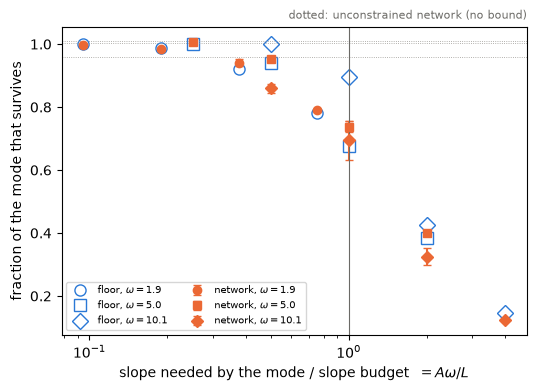

In [24]:
# Evaluation: how much of each noise mode survives, and how close the network gets to the clean target
def mode_amplitude(f, w):
    """Amplitude of the mode sin(w x) in f (w sits exactly on an FFT bin)."""
    omega, amp = fourier_spectrum(f, x_grid)
    return amp[np.argmin(np.abs(omega - w))]


print("Fraction of each noise mode that survives (network: mean ± std over seeds | floor)")
header = "".join(f"   omega={w:5.2f} (A*w={NOISE_AMPLITUDE * w:.2f})" for w in noise_omegas)
print(f"{'':16s}{header}")
survival = {}
for L in L_VALUES + [None]:
    row = []
    for w in noise_omegas:
        kept = np.array([mode_amplitude(predictions[L][s], w) for s in SEEDS]) / NOISE_AMPLITUDE
        survival[(L, w)] = kept
        text = f"{kept.mean():.2f} ± {kept.std():.2f}"
        if L is not None:
            text += f" | {mode_amplitude(floor_noisy[L], w) / NOISE_AMPLITUDE:.2f}"
        row.append(f"{text:>27s}")
    name = "unconstrained" if L is None else f"L = {L:g}"
    print(f"{name:16s}" + "".join(row))

# Denoising: distance to the CLEAN target (the noise alone has MSE = A^2 * n_modes / 2)
print("\nMSE to the clean target (lower = better denoising)")
print(f"  training data itself: {np.mean((noisy - target)**2):.2e}")
for L in L_VALUES + [None]:
    mse = np.array([np.mean((predictions[L][s] - target) ** 2) for s in SEEDS])
    name = "unconstrained" if L is None else f"L = {L:g}"
    floor_text = "" if L is None else f"   (floor: {np.mean((floor_noisy[L] - target)**2):.2e})"
    print(f"  {name:14s} {mse.mean():.2e} ± {mse.std():.1e}{floor_text}")

# Summary plot: surviving fraction against the slope a mode needs relative to the budget, A*omega / L
fig, ax = plt.subplots(figsize=(6, 4))
markers = ["o", "s", "D"]
for (w, m) in zip(noise_omegas, markers):
    r = [NOISE_AMPLITUDE * w / L for L in L_VALUES]
    kept = [survival[(L, w)] for L in L_VALUES]
    ax.errorbar(r, [k.mean() for k in kept], yerr=[k.std() for k in kept], fmt=m, color="#eb6834", ms=6,
                capsize=3, label=rf"network, $\omega = {w:.1f}$")
    ax.plot(r, [mode_amplitude(floor_noisy[L], w) / NOISE_AMPLITUDE for L in L_VALUES], m, mfc="none",
            color="#2a78d6", ms=8, label=rf"floor, $\omega = {w:.1f}$")
for (w, m) in zip(noise_omegas, markers):  # the unconstrained network as a reference: it should keep every mode
    kept = survival[(None, w)]
    ax.axhline(kept.mean(), color="#9a9893", lw=0.6, ls=":")
ax.axvline(1, color="#6b6a66", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel(r"slope needed by the mode / slope budget  $= A\omega / L$")
ax.set_ylabel("fraction of the mode that survives")
ax.set_title("dotted: unconstrained network (no bound)", loc="right", fontsize=8, color="#6b6a66")
ax.legend(fontsize=7, ncol=2)
plt.show()

# Outlier robustness
**Setup.** The clean target is a unit-area Gaussian ($\sigma = 1$, $L_\text{true} = 0.24$). On top of it we put three rectangular outlier spikes of height $\pm 1$: a single bad point, a burst of 5 points and a burst of 20 points.

**Prediction.** From the width law, a narrow feature of area $a$ is answered by an $L$-Lipschitz fit with a tent of height $\sqrt{aL}$. An outlier spike of height $h$ and width $w$ has area $a = |h|\,w$, so it can pull the fit away from the clean target by at most
$$ r_\text{max} = \min\!\left(|h|,\ \sqrt{aL}\right). $$
Narrow outliers are therefore suppressed automatically, and the suppression is controlled by $L$. Part of the slope budget can already be used by the target itself, so outliers on a steep flank are suppressed even more.

As before, we compare against the floor on the corrupted data (the ideal $L$-Lipschitz fit) and an unconstrained network of the same size. Networks: $L \in \{0.25, 0.5, 1, 2\}$ (all above $L_\text{true}$ of the clean target), 3 seeds each, width 64, depth 5. Runtime about 5 minutes.

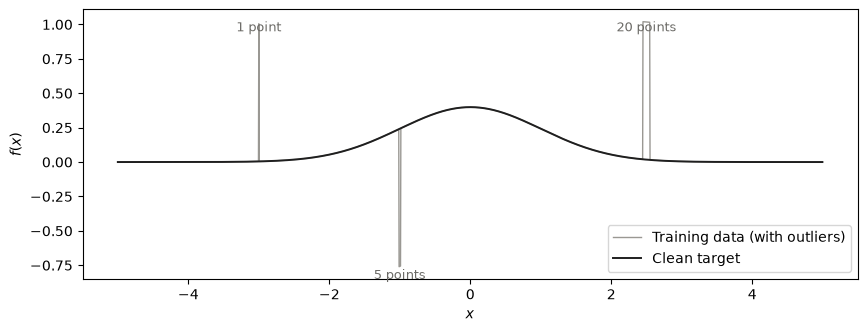

Outlier   width    area    predicted largest response sqrt(a*L) for L = 0.25, 0.5, 1, 2
x = -3.0   0.005   0.005   0.035   0.050   0.071   0.100
x = -1.0   0.025   0.025   0.079   0.112   0.158   0.224
x =  2.5   0.100   0.100   0.158   0.224   0.316   0.447


In [29]:
# Outlier robustness: clean target plus outlier spikes of different widths
from Toy_utils import train_full_batch
from lipschitz_floor import lipschitz_floor

X_RANGE_OUT = (-5, 5)
N_OUT = 2000
SIGMA_OUT = 1.0  # unit-area Gaussian, L_true = 0.24, so every L below fits the clean target itself

x_out = np.linspace(X_RANGE_OUT[0], X_RANGE_OUT[1], N_OUT, endpoint=False)
dx_out = x_out[1] - x_out[0]
clean_out = np.exp(-x_out**2 / (2 * SIGMA_OUT**2)) / (SIGMA_OUT * np.sqrt(2 * np.pi))

# Outliers: rectangular spikes of height h on top of the clean target. A spike of width w has area a = h * w.
OUTLIERS = [  # (centre, height, number of points)
    (-3.0, 1.0, 1),    # a single bad point
    (-1.0, -1.0, 5),   # a short burst
    (2.5, 1.0, 20),    # a longer burst
]
corrupted_out = clean_out.copy()
outlier_info = []
for centre, height, n_points in OUTLIERS:
    i0 = np.argmin(np.abs(x_out - centre)) - n_points // 2
    corrupted_out[i0:i0 + n_points] += height
    outlier_info.append(dict(centre=centre, height=height, n_points=n_points, width=n_points * dx_out,
                             area=abs(height) * n_points * dx_out))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(x_out, corrupted_out, color="#9a9893", lw=1.0, label="Training data (with outliers)")
ax.plot(x_out, clean_out, color="#1f1f1f", lw=1.4, label="Clean target")
for o in outlier_info:
    ax.annotate(f"{o['n_points']} point{'s' if o['n_points'] > 1 else ''}", (o["centre"], o["height"] * 0.9 + 0.05),
                ha="center", fontsize=9, color="#6b6a66")
ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$f(x)$"); ax.legend(loc="lower right")
plt.show()

# Prediction from the width law: an L-Lipschitz fit can answer a narrow spike of area a with a tent of height at
# most sqrt(a * L) (and never more than the spike height itself)
print("Outlier   width    area    predicted largest response sqrt(a*L) for L = " + ", ".join(f"{L:g}" for L in [0.25, 0.5, 1, 2]))
for o in outlier_info:
    pred = [min(abs(o["height"]), np.sqrt(o["area"] * L)) for L in [0.25, 0.5, 1, 2]]
    print(f"x = {o['centre']:4.1f}   {o['width']:.3f}   {o['area']:.3f}   " + "   ".join(f"{p:.3f}" for p in pred))

In [30]:
# Train Lipschitz networks (several L and seeds) and an unconstrained reference on the corrupted data
L_VALUES_OUT = [0.25, 0.5, 1.0, 2.0]
SEEDS_OUT = [0, 1, 2]
HIDDEN_DIM_OUT, N_GROUPS_OUT, DEPTH_OUT = 64, 8, 5

x_out_tensor = torch.tensor(x_out, dtype=torch.float32).unsqueeze(-1)
y_out_tensor = torch.tensor(corrupted_out, dtype=torch.float32).unsqueeze(-1)

predictions_out = {}  # predictions_out[L][seed], L = None is the unconstrained network
for L in L_VALUES_OUT + [None]:
    predictions_out[L] = {}
    for seed in SEEDS_OUT:
        torch.manual_seed(seed)
        if L is None:
            model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM_OUT, output_dim=1, depth=DEPTH_OUT)
        else:
            model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM_OUT, output_dim=1, n_groups=N_GROUPS_OUT,
                                   depth=DEPTH_OUT, lipschitz_bound=L)
        train_full_batch(model, x_out_tensor, y_out_tensor)
        with torch.no_grad():
            predictions_out[L][seed] = model(x_out_tensor).numpy().ravel()
    print(f"L = {L}: trained {len(SEEDS_OUT)} seeds")

# The ideal L-Lipschitz fit to the same corrupted data
floor_out = {L: lipschitz_floor(x_out, corrupted_out, L)[0] for L in L_VALUES_OUT}

L = 0.25: trained 3 seeds
L = 0.5: trained 3 seeds
L = 1.0: trained 3 seeds
L = 2.0: trained 3 seeds
L = None: trained 3 seeds


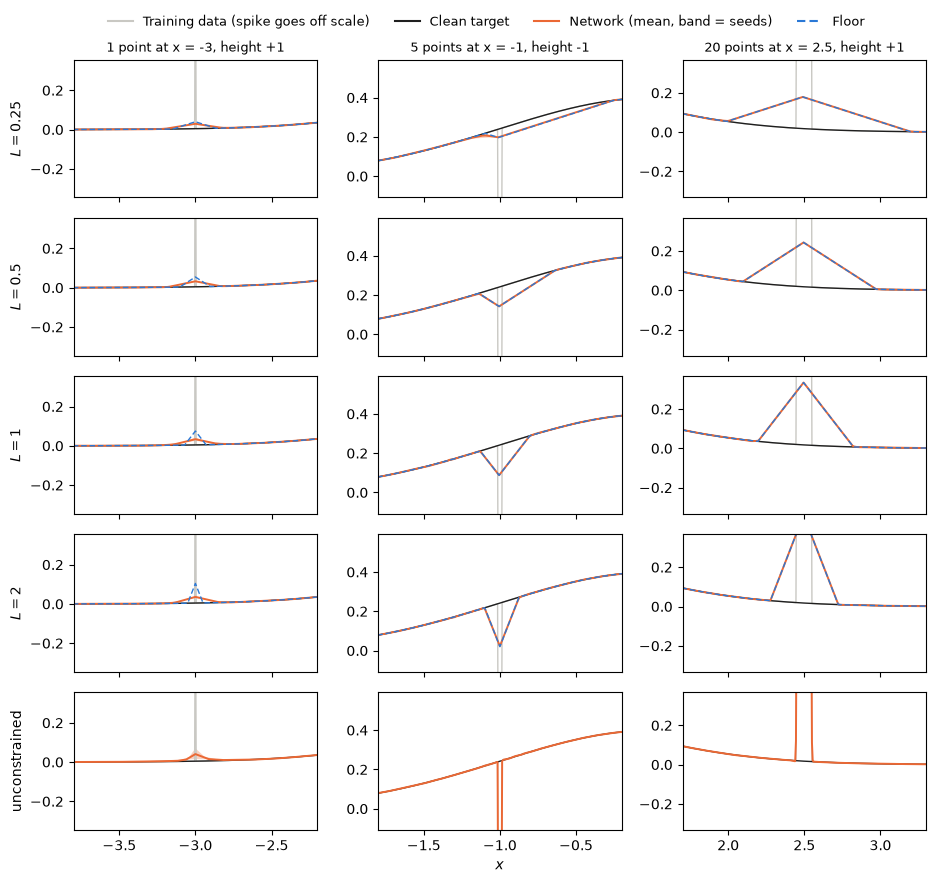

In [31]:
# Zoom on each outlier: one row per model, one column per outlier
WINDOW = 0.8  # half-width of the zoom window around each outlier
rows = L_VALUES_OUT + [None]
fig, axs = plt.subplots(len(rows), len(outlier_info), figsize=(11, 2.0 * len(rows)), sharex="col", sharey="col",
                        gridspec_kw=dict(hspace=0.15, wspace=0.25))
for r, L in enumerate(rows):
    preds = np.array([predictions_out[L][s] for s in SEEDS_OUT])
    for c, o in enumerate(outlier_info):
        ax = axs[r, c]
        ax.plot(x_out, corrupted_out, color="#c9c8c3", lw=1.0)
        ax.plot(x_out, clean_out, color="#1f1f1f", lw=1.0)
        ax.fill_between(x_out, preds.min(0), preds.max(0), color="#eb6834", alpha=0.3, lw=0)
        ax.plot(x_out, preds.mean(0), color="#eb6834", lw=1.4)
        if L is not None:
            ax.plot(x_out, floor_out[L], color="#2a78d6", lw=1.0, ls=(0, (4, 2)))
        ax.set_xlim(o["centre"] - WINDOW, o["centre"] + WINDOW)
        # Show the response, not the full spike height (the spike itself goes off the scale)
        base = np.interp(o["centre"], x_out, clean_out)
        ax.set_ylim(base - 0.35, base + 0.35)
        if r == 0:
            ax.set_title(f"{o['n_points']} point{'s' if o['n_points'] > 1 else ''} at x = {o['centre']:g}, "
                         f"height {o['height']:+g}", fontsize=9)
        if c == 0:
            ax.set_ylabel("unconstrained" if L is None else rf"$L = {L:g}$")
axs[-1, 1].set_xlabel(r"$x$")
fig.legend(handles=[plt.Line2D([], [], color="#c9c8c3", label="Training data (spike goes off scale)"),
                    plt.Line2D([], [], color="#1f1f1f", label="Clean target"),
                    plt.Line2D([], [], color="#eb6834", label="Network (mean, band = seeds)"),
                    plt.Line2D([], [], color="#2a78d6", ls=(0, (4, 2)), label="Floor")],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.9), frameon=False, fontsize=9)
plt.show()

Largest response to each outlier (network: mean ± std over seeds | floor | predicted sqrt(a*L))
L = 0.25         0.025 ± 0.002 | 0.035 | 0.035   0.041 ± 0.001 | 0.043 | 0.079   0.161 ± 0.000 | 0.161 | 0.158
L = 0.5          0.028 ± 0.002 | 0.050 | 0.050   0.098 ± 0.000 | 0.099 | 0.112   0.226 ± 0.000 | 0.226 | 0.224
L = 1            0.029 ± 0.007 | 0.071 | 0.071   0.153 ± 0.000 | 0.153 | 0.158   0.317 ± 0.000 | 0.317 | 0.316
L = 2            0.032 ± 0.004 | 0.100 | 0.100   0.219 ± 0.002 | 0.222 | 0.224   0.448 ± 0.000 | 0.448 | 0.447
unconstrained                    0.036 ± 0.023                   1.004 ± 0.001                   1.006 ± 0.005

MSE to the clean target (lower = more robust)
  corrupted data itself: 1.30e-02
  L = 0.25       1.18e-03 ± 4.6e-06   (floor: 1.19e-03)
  L = 0.5        1.69e-03 ± 3.1e-07   (floor: 1.70e-03)
  L = 1          2.39e-03 ± 3.8e-06   (floor: 2.40e-03)
  L = 2          3.36e-03 ± 3.3e-06   (floor: 3.39e-03)
  unconstrained  1.24e-02 ± 1.3e-04

Largest

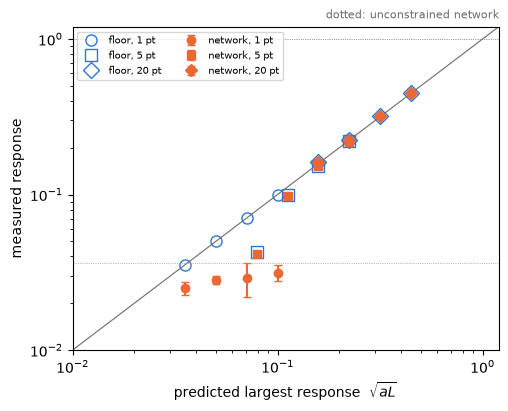

In [32]:
# Evaluation: how far each outlier pulls the fit away from the clean target, compared with the prediction sqrt(a*L)
def outlier_response(pred, o, window=0.5):
    """Largest deviation from the clean target near the outlier, in the direction of the outlier."""
    near = np.abs(x_out - o["centre"]) < window
    return np.max(np.sign(o["height"]) * (pred - clean_out)[near])


print("Largest response to each outlier (network: mean ± std over seeds | floor | predicted sqrt(a*L))")
response = {}
for L in L_VALUES_OUT + [None]:
    cells = []
    for k, o in enumerate(outlier_info):
        r = np.array([outlier_response(predictions_out[L][s], o) for s in SEEDS_OUT])
        response[(L, k)] = r
        text = f"{r.mean():.3f} ± {r.std():.3f}"
        if L is not None:
            text += f" | {outlier_response(floor_out[L], o):.3f} | {min(abs(o['height']), np.sqrt(o['area'] * L)):.3f}"
        cells.append(f"{text:>32s}")
    print(f"{'unconstrained' if L is None else f'L = {L:g}':14s}" + "".join(cells))

print("\nMSE to the clean target (lower = more robust)")
print(f"  corrupted data itself: {np.mean((corrupted_out - clean_out)**2):.2e}")
for L in L_VALUES_OUT + [None]:
    mse = np.array([np.mean((predictions_out[L][s] - clean_out) ** 2) for s in SEEDS_OUT])
    floor_text = "" if L is None else f"   (floor: {np.mean((floor_out[L] - clean_out)**2):.2e})"
    print(f"  {'unconstrained' if L is None else f'L = {L:g}':14s} {mse.mean():.2e} ± {mse.std():.1e}{floor_text}")

# Sensitivity: the largest slope of each fit. Fitting a spike makes a network very steep at its edges, so a tiny shift
# of the input near an outlier changes the output a lot. A Lipschitz network can never be steeper than L.
print("\nLargest slope of the fit (max |df/dx| on the grid), mean over seeds")
for L in L_VALUES_OUT + [None]:
    slopes = [np.abs(np.diff(predictions_out[L][s]) / dx_out).max() for s in SEEDS_OUT]
    bound = "" if L is None else f"   (bound L = {L:g})"
    print(f"  {'unconstrained' if L is None else f'L = {L:g}':14s} {np.mean(slopes):8.2f}{bound}")

# Summary plot: measured response against the prediction sqrt(a*L)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
markers = ["o", "s", "D"]
for k, (o, m) in enumerate(zip(outlier_info, markers)):
    predicted = [min(abs(o["height"]), np.sqrt(o["area"] * L)) for L in L_VALUES_OUT]
    ax.errorbar(predicted, [response[(L, k)].mean() for L in L_VALUES_OUT],
                yerr=[response[(L, k)].std() for L in L_VALUES_OUT], fmt=m, color="#eb6834", ms=6, capsize=3,
                label=f"network, {o['n_points']} pt")
    ax.plot(predicted, [outlier_response(floor_out[L], o) for L in L_VALUES_OUT], m, mfc="none", color="#2a78d6",
            ms=8, label=f"floor, {o['n_points']} pt")
    ax.axhline(response[(None, k)].mean(), color="#9a9893", lw=0.6, ls=":")
lims = [0.01, 1.2]
ax.plot(lims, lims, color="#6b6a66", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel(r"predicted largest response  $\sqrt{a L}$")
ax.set_ylabel("measured response")
ax.set_title("dotted: unconstrained network", loc="right", fontsize=8, color="#6b6a66")
ax.legend(fontsize=7, ncol=2, loc="upper left")
plt.show()

# Perturbations and data drift
**Setup.** A unit-area Gaussian ($\sigma = 0.5$, $L_\text{true} = 0.97$) with white noise ($0.03$) on the training labels. The networks only see $x \in [-1.5, 1.5]$. Two tests:

1. **Calibration drift.** Every input is measured as $x + \delta$ instead of $x$. An $L$-Lipschitz network guarantees $|f(x+\delta) - f(x)| \le L\delta$. The error against the truth is then bounded by
$$ |f(x+\delta) - f_\text{true}(x)| \;\le\; \underbrace{|f(x) - f_\text{true}(x)|}_{\text{bias, falls with } L} \;+\; \underbrace{L\,\delta}_{\text{sensitivity, grows with } L}, $$
   so the best $L$ should become smaller as the expected drift $\delta$ grows.
2. **Covariate shift.** Predictions outside the training range. An $L$-Lipschitz network can move away from its value at the edge of the training range by at most $L$ times the distance (a cone), whereas an unconstrained network has no such limit.

Networks: $L \in \{0.25, 0.5, 1, 2\}$ and an unconstrained reference, 3 seeds each, width 64, depth 5. Runtime about 5 minutes.

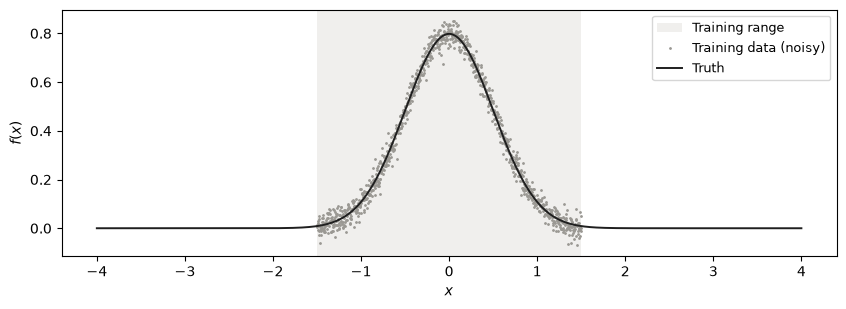

L_true of the target: 0.97


In [25]:
# Perturbations and data drift: noisy training data on a limited range, evaluated on a wider grid
from Toy_utils import train_full_batch

SIGMA_DRIFT = 0.5           # unit-area Gaussian: peak 0.80, L_true = 0.97
TRAIN_RANGE = (-1.5, 1.5)   # the networks only see this range
NOISE_DRIFT = 0.03          # white noise on the training labels
N_DRIFT = 1000


def gaussian_drift(x):
    return np.exp(-x**2 / (2 * SIGMA_DRIFT**2)) / (SIGMA_DRIFT * np.sqrt(2 * np.pi))


rng = np.random.default_rng(0)
x_drift_train = np.linspace(*TRAIN_RANGE, N_DRIFT)
y_drift_train = gaussian_drift(x_drift_train) + NOISE_DRIFT * rng.standard_normal(N_DRIFT)

# Evaluation grid: wider than the training range, regular spacing so a shift delta is a shift by whole grid steps
DX_EVAL = 0.005
x_eval = np.arange(-4, 4 + DX_EVAL / 2, DX_EVAL)
truth_eval = gaussian_drift(x_eval)
in_train = (x_eval >= TRAIN_RANGE[0]) & (x_eval <= TRAIN_RANGE[1])

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axvspan(*TRAIN_RANGE, color="#e6e5e1", alpha=0.6, lw=0, label="Training range")
ax.plot(x_drift_train, y_drift_train, ".", color="#9a9893", ms=2, label="Training data (noisy)")
ax.plot(x_eval, truth_eval, color="#1f1f1f", lw=1.4, label="Truth")
ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$f(x)$"); ax.legend(loc="upper right", fontsize=9)
plt.show()
print(f"L_true of the target: {gaussian_lipschitz_constant(SIGMA_DRIFT):.2f}")

In [26]:
# Train Lipschitz networks (several L and seeds) and an unconstrained reference on the noisy training range
L_VALUES_DRIFT = [0.25, 0.5, 1.0, 2.0]
SEEDS_DRIFT = [0, 1, 2]
HIDDEN_DIM_DRIFT, N_GROUPS_DRIFT, DEPTH_DRIFT = 64, 8, 5

x_drift_tensor = torch.tensor(x_drift_train, dtype=torch.float32).unsqueeze(-1)
y_drift_tensor = torch.tensor(y_drift_train, dtype=torch.float32).unsqueeze(-1)
x_eval_tensor = torch.tensor(x_eval, dtype=torch.float32).unsqueeze(-1)

predictions_drift = {}  # predictions_drift[L][seed] = network output on x_eval, L = None is unconstrained
for L in L_VALUES_DRIFT + [None]:
    predictions_drift[L] = {}
    for seed in SEEDS_DRIFT:
        torch.manual_seed(seed)
        if L is None:
            model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM_DRIFT, output_dim=1, depth=DEPTH_DRIFT)
        else:
            model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM_DRIFT, output_dim=1, n_groups=N_GROUPS_DRIFT,
                                   depth=DEPTH_DRIFT, lipschitz_bound=L)
        train_full_batch(model, x_drift_tensor, y_drift_tensor)
        with torch.no_grad():
            predictions_drift[L][seed] = model(x_eval_tensor).numpy().ravel()
    print(f"L = {L}: trained {len(SEEDS_DRIFT)} seeds")

L = 0.25: trained 3 seeds
L = 0.5: trained 3 seeds
L = 1.0: trained 3 seeds
L = 2.0: trained 3 seeds
L = None: trained 3 seeds


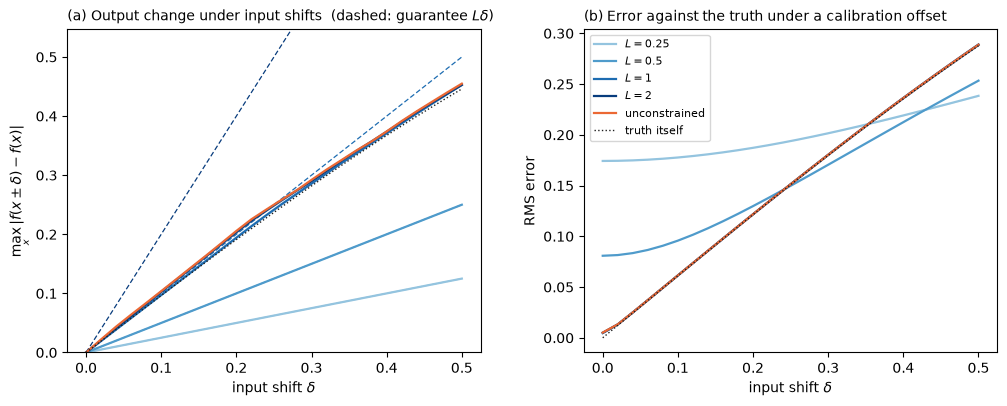

                  delta = 0.00  delta = 0.10  delta = 0.25  delta = 0.50
Output change (max)
  L = 0.25               0.000         0.025         0.060         0.125
  L = 0.5                0.000         0.050         0.120         0.250
  L = 1                  0.000         0.097         0.232         0.453
  L = 2                  0.000         0.103         0.240         0.453
  unconstrained          0.000         0.104         0.242         0.455
RMS error vs truth
  L = 0.25               0.174         0.178         0.192         0.238
  L = 0.5                0.081         0.096         0.146         0.253
  L = 1                  0.005         0.061         0.145         0.288
  L = 2                  0.005         0.061         0.145         0.289
  unconstrained          0.005         0.061         0.145         0.289


In [27]:
# Input perturbations / calibration drift: every input is measured as x + delta instead of x
deltas = np.arange(0, 0.5 + 1e-9, 4 * DX_EVAL)  # shifts in whole grid steps
idx_in = np.where(in_train)[0]


def shifted(f, k):
    """f evaluated at x + k * DX_EVAL for every x in the training range."""
    return f[idx_in + k]


def sensitivity(f):
    """Largest change of the output when the input moves by up to delta (both directions)."""
    out = []
    for d in deltas:
        k = int(round(d / DX_EVAL))
        out.append(max(np.abs(shifted(f, k) - f[idx_in]).max(), np.abs(shifted(f, -k) - f[idx_in]).max()))
    return np.array(out)


def drift_error(f):
    """RMS error against the truth when every input is shifted by +delta (a calibration offset)."""
    return np.array([np.sqrt(np.mean((shifted(f, int(round(d / DX_EVAL))) - truth_eval[idx_in]) ** 2))
                     for d in deltas])


models_drift = L_VALUES_DRIFT + [None]
colors_drift = dict(zip(L_VALUES_DRIFT, plt.cm.Blues(np.linspace(0.4, 0.95, len(L_VALUES_DRIFT)))))
colors_drift[None] = "#eb6834"
sens = {L: np.array([sensitivity(predictions_drift[L][s]) for s in SEEDS_DRIFT]) for L in models_drift}
derr = {L: np.array([drift_error(predictions_drift[L][s]) for s in SEEDS_DRIFT]) for L in models_drift}

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(wspace=0.25))
for L in models_drift:
    name = "unconstrained" if L is None else rf"$L = {L:g}$"
    for ax, values in [(axs[0], sens[L]), (axs[1], derr[L])]:
        ax.fill_between(deltas, values.min(0), values.max(0), color=colors_drift[L], alpha=0.25, lw=0)
        ax.plot(deltas, values.mean(0), color=colors_drift[L], lw=1.6, label=name)
    if L is not None:
        axs[0].plot(deltas, L * deltas, color=colors_drift[L], lw=0.9, ls=(0, (4, 2)))  # the guarantee L * delta
axs[0].plot(deltas, sensitivity(truth_eval), color="#1f1f1f", lw=1.0, ls=":", label="truth itself")
axs[1].plot(deltas, drift_error(truth_eval), color="#1f1f1f", lw=1.0, ls=":", label="truth itself")
axs[0].set_title("(a) Output change under input shifts  (dashed: guarantee $L\\delta$)", loc="left", fontsize=10)
axs[1].set_title("(b) Error against the truth under a calibration offset", loc="left", fontsize=10)
axs[0].set_ylabel(r"$\max_x |f(x \pm \delta) - f(x)|$"); axs[1].set_ylabel("RMS error")
axs[0].set_ylim(0, 1.2 * sens[None].max())
for ax in axs:
    ax.set_xlabel(r"input shift $\delta$")
axs[1].legend(fontsize=8)
plt.show()

print(f"{'':16s}" + "".join(f"  delta = {d:.2f}" for d in [0, 0.1, 0.25, 0.5]))
for title, table in [("Output change (max)", sens), ("RMS error vs truth", derr)]:
    print(title)
    for L in models_drift:
        idx = [int(np.argmin(np.abs(deltas - d))) for d in [0, 0.1, 0.25, 0.5]]
        print(f"  {'unconstrained' if L is None else f'L = {L:g}':14s}" + "".join(f"  {table[L].mean(0)[i]:12.3f}" for i in idx))

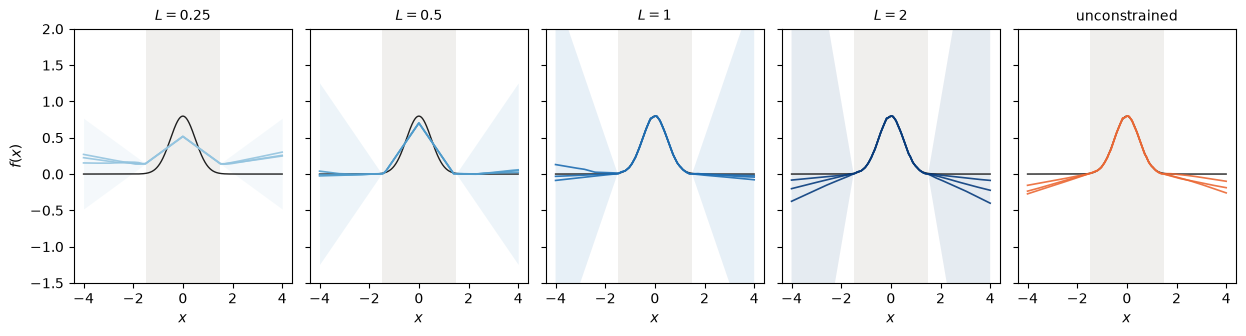

Outside the training range: largest |prediction - truth| and spread between seeds
  L = 0.25       max error  0.302   max seed spread  0.118
  L = 0.5        max error  0.059   max seed spread  0.066
  L = 1          max error  0.131   max seed spread  0.219
  L = 2          max error  0.401   max seed spread  0.314
  unconstrained  max error  0.273   max seed spread  0.160


In [28]:
# Covariate shift: predictions outside the training range. An L-Lipschitz network can move away from its value at the
# edge of the training range by at most L * distance (the cone); an unconstrained network has no such limit.
fig, axs = plt.subplots(1, len(models_drift), figsize=(15, 3.3), sharey=True, gridspec_kw=dict(wspace=0.08))
edges = [TRAIN_RANGE[0], TRAIN_RANGE[1]]
for ax, L in zip(axs, models_drift):
    ax.axvspan(*TRAIN_RANGE, color="#e6e5e1", alpha=0.6, lw=0)
    ax.plot(x_eval, truth_eval, color="#1f1f1f", lw=1.0)
    for s in SEEDS_DRIFT:
        ax.plot(x_eval, predictions_drift[L][s], color=colors_drift[L], lw=1.2, alpha=0.9)
    if L is not None:
        for edge in edges:  # cone from the mean prediction at each edge of the training range
            f_edge = np.mean([np.interp(edge, x_eval, predictions_drift[L][s]) for s in SEEDS_DRIFT])
            outside = x_eval[(x_eval >= edge) if edge > 0 else (x_eval <= edge)]
            ax.fill_between(outside, f_edge - L * np.abs(outside - edge), f_edge + L * np.abs(outside - edge),
                            color=colors_drift[L], alpha=0.10, lw=0)
    ax.set_title("unconstrained" if L is None else rf"$L = {L:g}$", fontsize=10)
    ax.set_xlabel(r"$x$")
axs[0].set_ylabel(r"$f(x)$")
axs[0].set_ylim(-1.5, 2.0)
plt.show()

print("Outside the training range: largest |prediction - truth| and spread between seeds")
outside_mask = ~in_train
for L in models_drift:
    preds = np.array([predictions_drift[L][s] for s in SEEDS_DRIFT])
    err = np.abs(preds - truth_eval)[:, outside_mask].max()
    spread = (preds.max(0) - preds.min(0))[outside_mask].max()
    print(f"  {'unconstrained' if L is None else f'L = {L:g}':14s} max error {err:6.3f}   max seed spread {spread:6.3f}")

# Two-peak resolution (Rayleigh-type criterion)
**Question.** When can an $L$-Lipschitz model still show two nearby peaks as two, rather than merging them into one?

**Setup.** Two equal unit-area Gaussians ($\sigma = 0.05$) at separation $d$. As a measure of resolution we use the *relative dip* between the two maxima: $1$ means the fit drops to zero between the peaks, $0$ means the peaks have merged. We call two peaks resolved when the dip is at least $0.1$ (any threshold works; the scaling is what matters).

**Prediction.** From the width law, each narrow peak becomes a tent of height $\sqrt{L}$ and half-width $w_L = 1/\sqrt{L}$ (unit area). Two such tents stop overlapping, and the fit drops to zero between them, exactly at
$$ d = 2\,w_L . $$
Below that the tents merge, so the separation needed to resolve the peaks should scale as $d_\text{min} \propto w_L = 1/\sqrt{L}$, as long as $w_L$ is large compared with the true peak width. When $w_L$ becomes comparable to the true width, the peaks themselves set the limit (the truth has no dip at all for $d < 2\sigma$).

1. **Phase map (floor only, no training):** the dip of the best possible $L$-Lipschitz fit for a grid of $d$ and $L$. Plotted against $d / w_L$, all $L$ should fall on one curve. Runtime about 3 minutes.
2. **Networks:** $L = 10$ ($w_L = 0.32$) at four separations around the boundary, 3 seeds each, plus one unconstrained reference per separation. Runtime about 6 minutes.

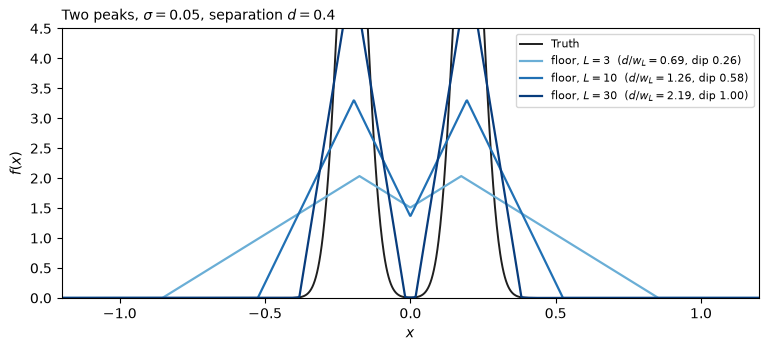

In [33]:
# Two-peak resolution: two equal unit-area Gaussians at separation d
from lipschitz_floor import lipschitz_floor

SIGMA_RAY = 0.05      # narrow peaks: L_true of a single peak is about 97
X_RANGE_RAY = (-3, 3)
N_RAY = 3000          # grid spacing 0.002, i.e. 25 points per sigma

x_ray = np.linspace(X_RANGE_RAY[0], X_RANGE_RAY[1], N_RAY)


def two_peaks(x, d, sigma=SIGMA_RAY):
    """Two unit-area Gaussians centred at -d/2 and +d/2."""
    g = lambda m: np.exp(-(x - m)**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))
    return g(-d / 2) + g(d / 2)


def relative_dip(f, x=x_ray):
    """
    How deep the valley between the two peaks is, relative to the lower of the two maxima.
    1 = the fit drops to zero between the peaks (fully resolved), 0 = no dip (the peaks have merged).
    """
    left, right = x < 0, x >= 0
    i_left = np.where(left)[0][np.argmax(f[left])]
    i_right = np.where(right)[0][np.argmax(f[right])]
    valley = f[i_left:i_right + 1].min()
    top = min(f[i_left], f[i_right])
    return max(0.0, 1 - valley / top) if top > 0 else 0.0


# Example: what the floor does to two peaks for a few L at a fixed separation
D_EXAMPLE = 0.4
y_example = two_peaks(x_ray, D_EXAMPLE)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(x_ray, y_example, color="#1f1f1f", lw=1.4, label="Truth")
for L, c in zip([3, 10, 30], plt.cm.Blues([0.5, 0.75, 0.95])):
    g, _ = lipschitz_floor(x_ray, y_example, L)
    w_L = 1 / np.sqrt(L)
    ax.plot(x_ray, g, color=c, lw=1.6, label=rf"floor, $L = {L}$  ($d / w_L = {D_EXAMPLE / w_L:.2f}$, dip {relative_dip(g):.2f})")
ax.set_xlim(-1.2, 1.2); ax.set_ylim(0, 4.5)
ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$f(x)$")
ax.set_title(rf"Two peaks, $\sigma = {SIGMA_RAY}$, separation $d = {D_EXAMPLE}$", loc="left", fontsize=10)
ax.legend(fontsize=8, loc="upper right")
fig.savefig("Plots/two_peak_example.pdf", bbox_inches="tight")
plt.show()

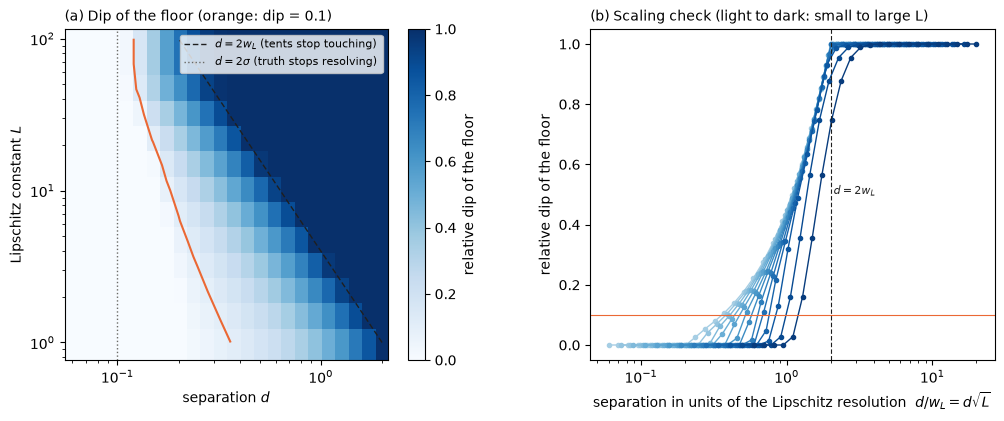

L        d at dip = 0.1    in units of w_L
   1.0        0.374         0.37
   1.5        0.321         0.39
   2.2        0.321         0.47
   3.2        0.276         0.49
   4.6        0.237         0.51
   6.8        0.203         0.53
  10.0        0.203         0.64
  14.7        0.174         0.67
  21.5        0.150         0.70
  31.6        0.150         0.84
  46.4        0.129         0.88
  68.1        0.129         1.06
 100.0        0.129         1.29


In [34]:
# Phase map: relative dip of the floor for a grid of separations d and Lipschitz constants L (no training needed)
d_grid = np.geomspace(0.06, 2.0, 24)
L_grid = np.geomspace(1, 100, 13)
dip_floor = np.zeros((len(L_grid), len(d_grid)))
dip_truth = np.array([relative_dip(two_peaks(x_ray, d)) for d in d_grid])
for i, L in enumerate(L_grid):
    for j, d in enumerate(d_grid):
        dip_floor[i, j] = relative_dip(lipschitz_floor(x_ray, two_peaks(x_ray, d), L)[0])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw=dict(wspace=0.3))

# (a) Phase map in (d, L)
ax = axs[0]
mesh = ax.pcolormesh(d_grid, L_grid, dip_floor, cmap="Blues", vmin=0, vmax=1, shading="nearest")
fig.colorbar(mesh, ax=ax, label="relative dip of the floor")
ax.contour(d_grid, L_grid, dip_floor, levels=[0.1], colors="#eb6834", linewidths=1.5)
ax.plot(2 / np.sqrt(L_grid), L_grid, color="#1f1f1f", lw=1.0, ls=(0, (4, 2)),
        label=r"$d = 2 w_L$ (tents stop touching)")
ax.axvline(2 * SIGMA_RAY, color="#6b6a66", lw=1.0, ls=":", label=r"$d = 2\sigma$ (truth stops resolving)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"separation $d$"); ax.set_ylabel(r"Lipschitz constant $L$")
ax.set_title("(a) Dip of the floor (orange: dip = 0.1)", loc="left", fontsize=10)
ax.legend(fontsize=8, loc="upper right")

# (b) The same data against d / w_L: if the scaling holds, all L fall on one curve
ax = axs[1]
colors = plt.cm.Blues(np.linspace(0.35, 0.95, len(L_grid)))
for i, (L, c) in enumerate(zip(L_grid, colors)):
    ax.plot(d_grid * np.sqrt(L), dip_floor[i], "o-", color=c, ms=3, lw=1.0)
ax.axhline(0.1, color="#eb6834", lw=0.8)
ax.axvline(2, color="#1f1f1f", lw=0.8, ls=(0, (4, 2)))
ax.text(2.1, 0.5, r"$d = 2 w_L$", fontsize=8, color="#1f1f1f")
ax.set_xscale("log")
ax.set_xlabel(r"separation in units of the Lipschitz resolution  $d / w_L = d\sqrt{L}$")
ax.set_ylabel("relative dip of the floor")
ax.set_title("(b) Scaling check (light to dark: small to large L)", loc="left", fontsize=10)
fig.savefig("Plots/two_peak_phase_map.pdf", bbox_inches="tight")
plt.show()

# Where does the dip pass 0.1, in units of w_L, for each L?
print("L        d at dip = 0.1    in units of w_L")
for i, L in enumerate(L_grid):
    above = np.where(dip_floor[i] >= 0.1)[0]
    if len(above):
        d_min = d_grid[above[0]]
        print(f"{L:6.1f}   {d_min:10.3f}       {d_min * np.sqrt(L):6.2f}")

In [35]:
# Do trained networks resolve two peaks like the floor? L = 10 (w_L = 0.32) at separations around the boundary
from Toy_utils import train_full_batch

L_RAY = 10.0
D_RAY = [0.15, 0.25, 0.4, 0.65]   # d / w_L = 0.47, 0.79, 1.26, 2.06
SEEDS_RAY = [0, 1, 2]
HIDDEN_DIM_RAY, N_GROUPS_RAY, DEPTH_RAY = 64, 8, 5

x_ray_tensor = torch.tensor(x_ray, dtype=torch.float32).unsqueeze(-1)
results_ray = {}  # results_ray[d] = dict with truth, floor, Lipschitz predictions (per seed) and unconstrained
for d in D_RAY:
    y = two_peaks(x_ray, d)
    y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(-1)
    preds = []
    for seed in SEEDS_RAY:
        torch.manual_seed(seed)
        model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM_RAY, output_dim=1, n_groups=N_GROUPS_RAY,
                               depth=DEPTH_RAY, lipschitz_bound=L_RAY)
        train_full_batch(model, x_ray_tensor, y_tensor)
        with torch.no_grad():
            preds.append(model(x_ray_tensor).numpy().ravel())
    torch.manual_seed(0)
    reference = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM_RAY, output_dim=1, depth=DEPTH_RAY)
    train_full_batch(reference, x_ray_tensor, y_tensor)
    with torch.no_grad():
        unconstrained = reference(x_ray_tensor).numpy().ravel()
    results_ray[d] = dict(truth=y, floor=lipschitz_floor(x_ray, y, L_RAY)[0], lipschitz=np.array(preds),
                          unconstrained=unconstrained)
    print(f"d = {d}: trained")

d = 0.15: trained
d = 0.25: trained
d = 0.4: trained
d = 0.65: trained


Relative dip at L = 10 (w_L = 0.32): network mean ± std over seeds | floor | truth | unconstrained
  d = 0.15 (d/w_L = 0.47):  0.00 ± 0.00 | 0.00 | 0.36 | 0.38
  d = 0.25 (d/w_L = 0.79):  0.27 ± 0.00 | 0.27 | 0.91 | 0.00
  d = 0.40 (d/w_L = 1.26):  0.58 ± 0.00 | 0.58 | 1.00 | 1.00
  d = 0.65 (d/w_L = 2.06):  1.00 ± 0.00 | 1.00 | 1.00 | 1.00


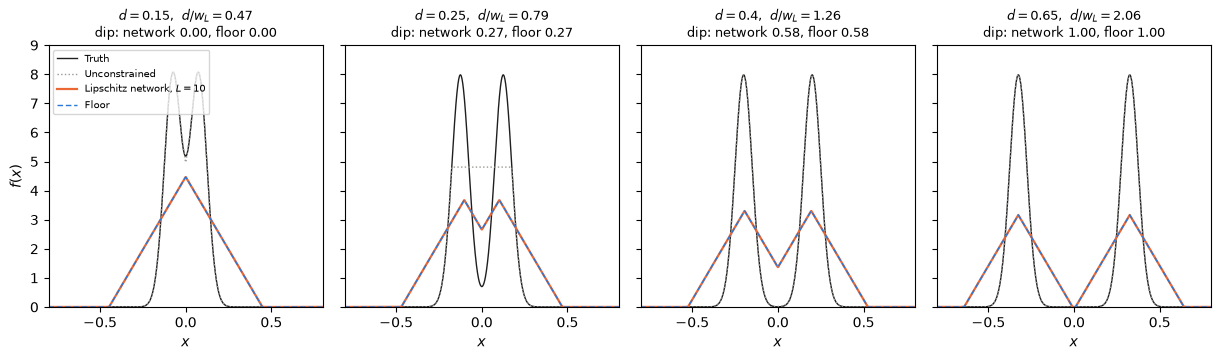

In [36]:
# Fits and dips for each separation
w_L = 1 / np.sqrt(L_RAY)
fig, axs = plt.subplots(1, len(D_RAY), figsize=(15, 3.4), sharey=True, gridspec_kw=dict(wspace=0.08))
print(f"Relative dip at L = {L_RAY:g} (w_L = {w_L:.2f}): network mean ± std over seeds | floor | truth | unconstrained")
for ax, d in zip(axs, D_RAY):
    r = results_ray[d]
    dips = np.array([relative_dip(p) for p in r["lipschitz"]])
    ax.plot(x_ray, r["truth"], color="#1f1f1f", lw=1.0, label="Truth")
    ax.plot(x_ray, r["unconstrained"], color="#9a9893", lw=1.0, ls=":", label="Unconstrained")
    ax.fill_between(x_ray, r["lipschitz"].min(0), r["lipschitz"].max(0), color="#eb6834", alpha=0.3, lw=0)
    ax.plot(x_ray, r["lipschitz"].mean(0), color="#eb6834", lw=1.6, label=rf"Lipschitz network, $L = {L_RAY:g}$")
    ax.plot(x_ray, r["floor"], color="#2a78d6", lw=1.0, ls=(0, (4, 2)), label="Floor")
    ax.set_xlim(-0.8, 0.8); ax.set_ylim(0, 9)
    ax.set_title(rf"$d = {d}$,  $d / w_L = {d / w_L:.2f}$" + f"\ndip: network {dips.mean():.2f}, floor {relative_dip(r['floor']):.2f}",
                 fontsize=9)
    ax.set_xlabel(r"$x$")
    print(f"  d = {d:4.2f} (d/w_L = {d / w_L:4.2f}):  {dips.mean():.2f} ± {dips.std():.2f} | {relative_dip(r['floor']):.2f} | "
          f"{relative_dip(r['truth']):.2f} | {relative_dip(r['unconstrained']):.2f}")
axs[0].set_ylabel(r"$f(x)$")
axs[0].legend(fontsize=7, loc="upper left")
fig.savefig("Plots/two_peak_networks.pdf", bbox_inches="tight")
plt.show()